Working directory: /Users/naimahughley/Desktop/POSM_CoilPCB/POSM_6mm_Magpylib_Verification_Package/field_simulation
Coil folder found: True
Geometry file found: True

Geometry loaded successfully!
Magpylib version: 5.0.1
Number of vertices: 33325


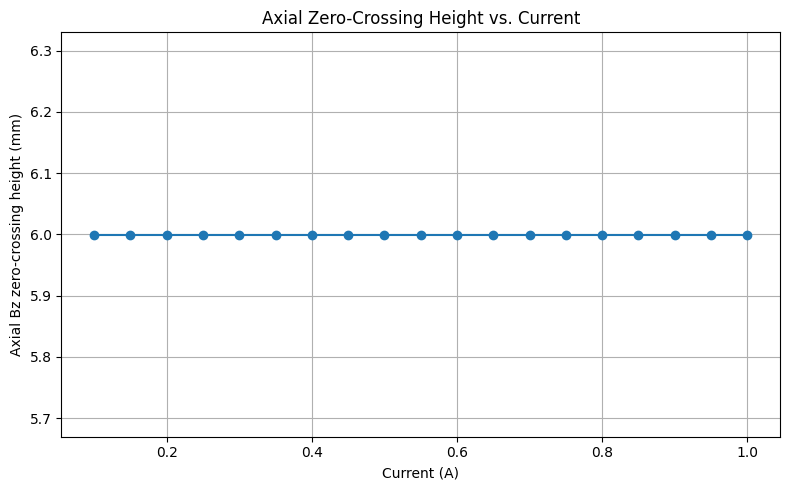

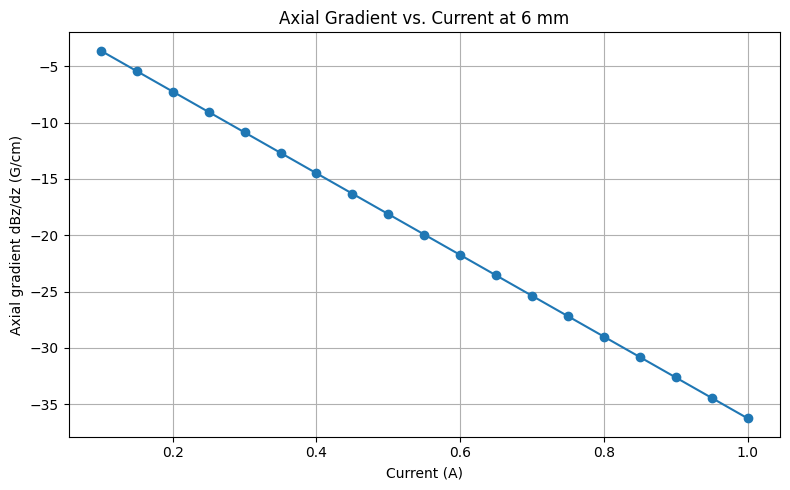


RESULTS
 Current (A) |  Zero height (mm) |  Gradient (G/cm)
----------------------------------------------------------
        0.10 |            5.9997 |          -3.6248
        0.15 |            5.9997 |          -5.4371
        0.20 |            5.9997 |          -7.2495
        0.25 |            5.9997 |          -9.0619
        0.30 |            5.9997 |         -10.8743
        0.35 |            5.9997 |         -12.6867
        0.40 |            5.9997 |         -14.4990
        0.45 |            5.9997 |         -16.3114
        0.50 |            5.9997 |         -18.1238
        0.55 |            5.9997 |         -19.9362
        0.60 |            5.9997 |         -21.7486
        0.65 |            5.9997 |         -23.5609
        0.70 |            5.9997 |         -25.3733
        0.75 |            5.9997 |         -27.1857
        0.80 |            5.9997 |         -28.9981
        0.85 |            5.9997 |         -30.8105
        0.90 |            5.9997 |         -32.6

In [1]:

from pathlib import Path
import numpy as np
import magpylib as magpy
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ==================================================
# 1. LOAD THE 6 mm COIL PCB GEOMETRY
# ==================================================
folder = Path.cwd() / "DENSE_06mm_8Cu_7WINDING_LAYERS"
vertices_file = folder / "vertices_closed_m.txt"

print("Working directory:", Path.cwd())
print("Coil folder found:", folder.exists())
print("Geometry file found:", vertices_file.exists())

if not vertices_file.exists():
    raise FileNotFoundError(
        "The geometry file was not found. "
        "Check the working directory printed above."
    )

vertices = np.loadtxt(vertices_file)
vertices = np.asarray(vertices).reshape(-1, 3)

coil = magpy.current.Polyline(
    current=1.0,
    vertices=vertices
)

print("\nGeometry loaded successfully!")
print("Magpylib version:", magpy.__version__)
print("Number of vertices:", len(vertices))

# ==================================================
# 2. SET SIMULATION PARAMETERS
# ==================================================
currents = np.linspace(0.1, 1.0, 19)
heights_mm = np.linspace(0.5, 20.0, 300)

# 10 micrometers, expressed in meters
dz = 1e-5

# ==================================================
# 3. MAGNETIC FIELD Bz IN GAUSS
# ==================================================
def bz_gauss(height_mm, current_A):
    point = np.array([[0, 0, height_mm / 1000]])

    field = np.asarray(coil.getB(point)).reshape(-1, 3)

    # Magpylib field is calculated for 1 A.
    # Scale linearly to the requested current.
    return field[0, 2] * 1e4 * current_A

# ==================================================
# 4. AXIAL GRADIENT dBz/dz IN G/cm
# ==================================================
def gradient_g_cm(height_mm, current_A):
    z = height_mm / 1000

    points = np.array([
        [0, 0, z - dz],
        [0, 0, z + dz]
    ])

    field = np.asarray(coil.getB(points)).reshape(-1, 3)
    bz = field[:, 2] * 1e4 * current_A

    return (bz[1] - bz[0]) / (2 * dz * 100)

# ==================================================
# 5. FIND AXIAL ZERO-CROSSING HEIGHT
# ==================================================
zero_heights = []

for current in currents:
    fields = np.array([
        bz_gauss(height, current)
        for height in heights_mm
    ])

    zero = np.nan

    for i in range(len(heights_mm) - 1):
        if fields[i] * fields[i + 1] < 0:
            zero = brentq(
                lambda h: bz_gauss(h, current),
                heights_mm[i],
                heights_mm[i + 1]
            )
            break

    zero_heights.append(zero)

# ==================================================
# 6. PLOT ZERO-POINT HEIGHT VS CURRENT
# ==================================================
plt.figure(figsize=(8, 5))
plt.plot(currents, zero_heights, "o-")
plt.xlabel("Current (A)")
plt.ylabel("Axial Bz zero-crossing height (mm)")
plt.title("Axial Zero-Crossing Height vs. Current")
plt.grid(True)
plt.tight_layout()
plt.savefig("height_vs_current.png", dpi=200)
plt.show()

# ==================================================
# 7. PLOT GRADIENT VS CURRENT AT 6 mm
# ==================================================
gradients = [
    gradient_g_cm(6.0, current)
    for current in currents
]

plt.figure(figsize=(8, 5))
plt.plot(currents, gradients, "o-")
plt.xlabel("Current (A)")
plt.ylabel("Axial gradient dBz/dz (G/cm)")
plt.title("Axial Gradient vs. Current at 6 mm")
plt.grid(True)
plt.tight_layout()
plt.savefig("gradient_vs_current.png", dpi=200)
plt.show()

# ==================================================
# 8. PRINT RESULTS TABLE
# ==================================================
print("\nRESULTS")
print("=" * 58)
print(f"{'Current (A)':>12} | {'Zero height (mm)':>17} | {'Gradient (G/cm)':>16}")
print("-" * 58)

for current, height, grad in zip(
    currents, zero_heights, gradients
):
    height_text = (
        f"{height:.4f}" if np.isfinite(height)
        else "No crossing"
    )

    print(
        f"{current:12.2f} | "
        f"{height_text:>17} | "
        f"{grad:16.4f}"
    )

print("\nSaved plots:")
print("height_vs_current.png")
print("gradient_vs_current.png")


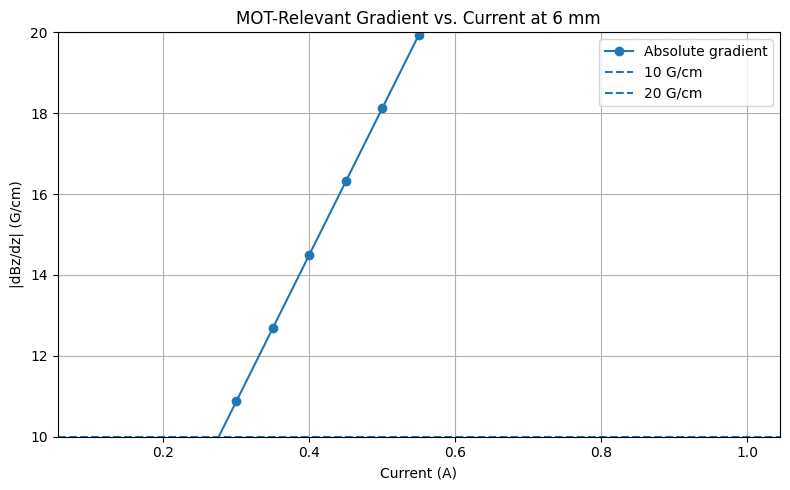

Absolute gradient at 1 A: 36.2476 G/cm

Currents within the 10–20 G/cm range:
0.300 A -> 10.874 G/cm
0.350 A -> 12.687 G/cm
0.400 A -> 14.499 G/cm
0.450 A -> 16.311 G/cm
0.500 A -> 18.124 G/cm
0.550 A -> 19.936 G/cm

Saved: abs_gradient_MOT_range.png


In [3]:

from pathlib import Path
import numpy as np
import magpylib as magpy
import matplotlib.pyplot as plt

# Load the 6 mm coil geometry
folder = Path.cwd() / "DENSE_06mm_8Cu_7WINDING_LAYERS"
vertices_file = folder / "vertices_closed_m.txt"

vertices = np.asarray(np.loadtxt(vertices_file)).reshape(-1, 3)

coil = magpy.current.Polyline(
    current=1.0,
    vertices=vertices
)

# Calculate the axial gradient at 6 mm for 1 A
z = 0.006  # 6 mm in meters
dz = 1e-5  # small distance in meters

points = np.array([
    [0, 0, z - dz],
    [0, 0, z + dz]
])

field = np.asarray(coil.getB(points)).reshape(-1, 3)
bz_gauss = field[:, 2] * 1e4

gradient_1A = (bz_gauss[1] - bz_gauss[0]) / (2 * dz * 100)

# Scale gradient for currents from 0.1 A to 1.0 A
currents = np.linspace(0.1, 1.0, 19)
abs_gradients = np.abs(gradient_1A * currents)

# Plot only the MOT-relevant 10–20 G/cm region
plt.figure(figsize=(8, 5))
plt.plot(currents, abs_gradients, "o-", label="Absolute gradient")
plt.axhline(10, linestyle="--", label="10 G/cm")
plt.axhline(20, linestyle="--", label="20 G/cm")

plt.ylim(10, 20)
plt.xlabel("Current (A)")
plt.ylabel("|dBz/dz| (G/cm)")
plt.title("MOT-Relevant Gradient vs. Current at 6 mm")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("abs_gradient_MOT_range.png", dpi=200)
plt.show()

# Print currents inside the target range
print(f"Absolute gradient at 1 A: {abs(gradient_1A):.4f} G/cm")
print("\nCurrents within the 10–20 G/cm range:")

in_range = (abs_gradients >= 10) & (abs_gradients <= 20)

if np.any(in_range):
    for current, gradient in zip(currents[in_range], abs_gradients[in_range]):
        print(f"{current:.3f} A -> {gradient:.3f} G/cm")
else:
    print("No sampled current is within the target range.")

print("\nSaved: abs_gradient_MOT_range.png")


Loaded coil geometry: 33,325 vertices
Calculating gradient along the central axis...
Calculation complete!


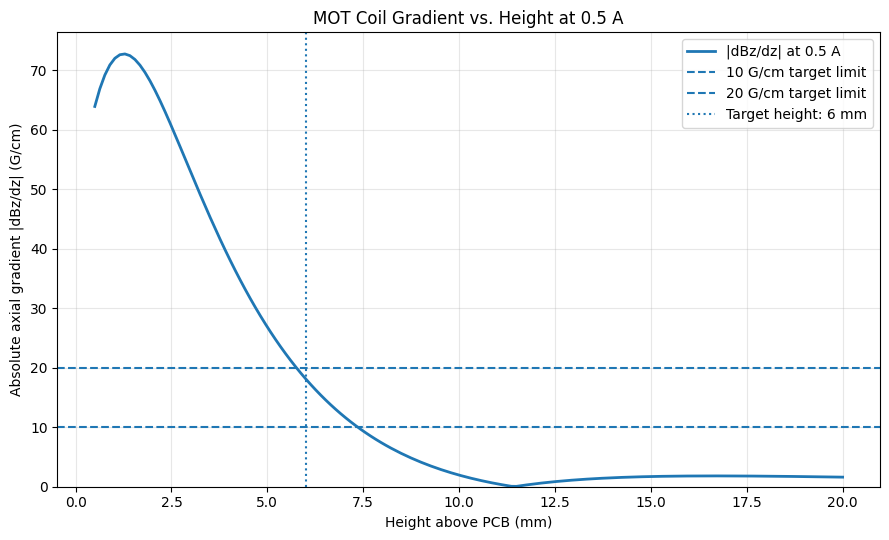


Selected results at 0.5 A
-------------------------------------------
 Height (mm) |  |Gradient| (G/cm)
-------------------------------------------
        1.94 |            68.2036
        4.03 |            38.0064
        6.00 |            18.1487
        7.96 |             7.4489
       10.05 |             1.8586
       12.02 |             0.5171
       15.03 |             1.7161
       20.00 |             1.6107

Saved plot: gradient_vs_height_0p5A.png


In [4]:

from pathlib import Path
import numpy as np
import magpylib as magpy
import matplotlib.pyplot as plt

# ============================================
# 1. Load the 6 mm MOT coil geometry
# ============================================
folder = Path.cwd() / "DENSE_06mm_8Cu_7WINDING_LAYERS"
vertices_file = folder / "vertices_closed_m.txt"

if not vertices_file.exists():
    raise FileNotFoundError(
        f"Cannot find coil geometry: {vertices_file}\n"
        "Check that Jupyter is running from field_simulation."
    )

vertices = np.asarray(np.loadtxt(vertices_file)).reshape(-1, 3)

coil = magpy.current.Polyline(
    current=1.0,
    vertices=vertices
)

print(f"Loaded coil geometry: {len(vertices):,} vertices")

# ============================================
# 2. Set current and height range
# ============================================
current_A = 0.5
heights_mm = np.linspace(0.5, 20.0, 150)

# Calculate derivative using points just below and above each height
dz = 1e-5  # meters

z_m = heights_mm / 1000

points_below = np.column_stack([
    np.zeros(len(z_m)),
    np.zeros(len(z_m)),
    z_m - dz
])

points_above = np.column_stack([
    np.zeros(len(z_m)),
    np.zeros(len(z_m)),
    z_m + dz
])

# ============================================
# 3. Calculate axial gradient in G/cm
# ============================================
print("Calculating gradient along the central axis...")

B_below = np.asarray(coil.getB(points_below)).reshape(-1, 3)
B_above = np.asarray(coil.getB(points_above)).reshape(-1, 3)

# Magpylib returns tesla; convert to gauss and scale to 0.5 A
Bz_below_G = B_below[:, 2] * 1e4 * current_A
Bz_above_G = B_above[:, 2] * 1e4 * current_A

# dBz/dz in G/cm
gradient_G_cm = (
    (Bz_above_G - Bz_below_G) / (2 * dz * 100)
)

abs_gradient = np.abs(gradient_G_cm)

print("Calculation complete!")

# ============================================
# 4. Plot absolute gradient vs height
# ============================================
plt.figure(figsize=(9, 5.5))

plt.plot(
    heights_mm,
    abs_gradient,
    linewidth=2,
    label="|dBz/dz| at 0.5 A"
)

plt.axhline(
    10, linestyle="--",
    label="10 G/cm target limit"
)

plt.axhline(
    20, linestyle="--",
    label="20 G/cm target limit"
)

# Highlight the intended 6 mm height
plt.axvline(
    6, linestyle=":",
    label="Target height: 6 mm"
)

plt.xlabel("Height above PCB (mm)")
plt.ylabel("Absolute axial gradient |dBz/dz| (G/cm)")
plt.title("MOT Coil Gradient vs. Height at 0.5 A")
plt.ylim(bottom=0)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("gradient_vs_height_0p5A.png", dpi=200)
plt.show()

# ============================================
# 5. Report values at selected heights
# ============================================
print("\nSelected results at 0.5 A")
print("-" * 43)
print(f"{'Height (mm)':>12} | {'|Gradient| (G/cm)':>18}")
print("-" * 43)

for target_height in [2, 4, 6, 8, 10, 12, 15, 20]:
    idx = np.argmin(np.abs(heights_mm - target_height))
    print(
        f"{heights_mm[idx]:12.2f} | "
        f"{abs_gradient[idx]:18.4f}"
    )

print("\nSaved plot: gradient_vs_height_0p5A.png")


Loaded 33,325 vertices
Calculating the magnetic field...
Field calculation complete!


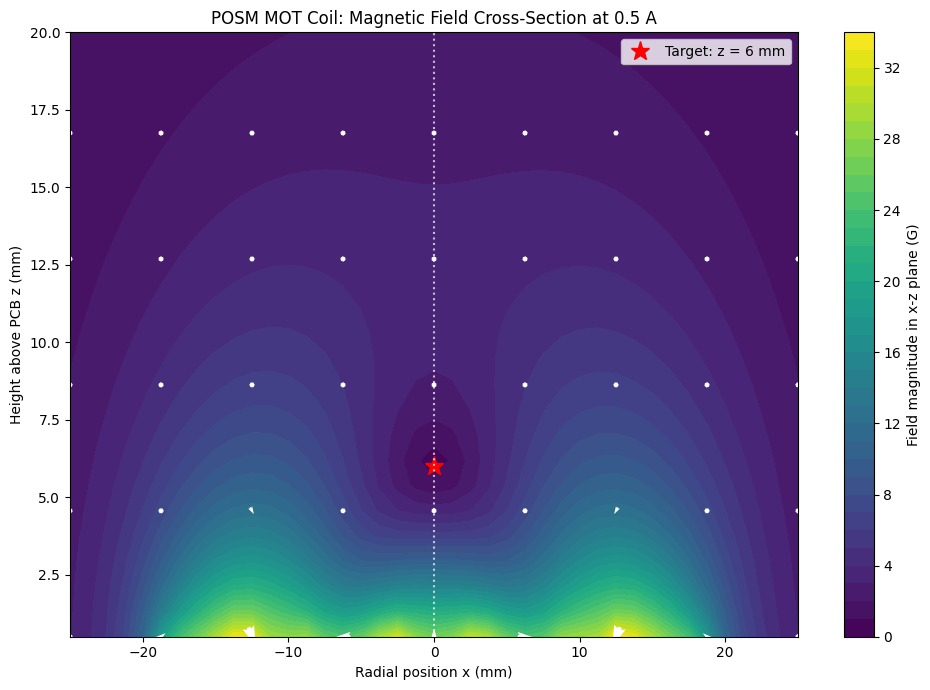

Saved: field_vector_map_0p5A.png


In [6]:

from pathlib import Path
import numpy as np
import magpylib as magpy
import matplotlib.pyplot as plt

# ============================================
# 1. Load the coil geometry
# ============================================
vertices_file = (
    Path.cwd()
    / "DENSE_06mm_8Cu_7WINDING_LAYERS"
    / "vertices_closed_m.txt"
)

if not vertices_file.exists():
    raise FileNotFoundError(
        f"Cannot find geometry file: {vertices_file}\n"
        "Run Jupyter from the field_simulation folder."
    )

vertices = np.asarray(np.loadtxt(vertices_file)).reshape(-1, 3)

coil = magpy.current.Polyline(
    current=1.0,
    vertices=vertices
)

print(f"Loaded {len(vertices):,} vertices")

# ============================================
# 2. Set current and create an r-z grid
# ============================================
current_A = 0.5

r_mm = np.linspace(-25, 25, 41)
z_mm = np.linspace(0.5, 20, 25)

R_mm, Z_mm = np.meshgrid(r_mm, z_mm)

# The cross-section is the x-z plane, with y = 0.
points = np.column_stack([
    (R_mm.ravel() / 1000),
    np.zeros(R_mm.size),
    (Z_mm.ravel() / 1000)
])

print("Calculating the magnetic field...")

# The geometry is defined at 1 A, so scale to 0.5 A.
B = np.asarray(coil.getB(points)).reshape(-1, 3) * current_A

Bx = B[:, 0].reshape(R_mm.shape) * 1e4  # gauss
Bz = B[:, 2].reshape(R_mm.shape) * 1e4  # gauss

Bmag = np.sqrt(Bx**2 + Bz**2)

print("Field calculation complete!")

# ============================================
# 3. Plot field strength and direction
# ============================================
fig, ax = plt.subplots(figsize=(10, 7))

# Background colors show field magnitude.
contour = ax.contourf(
    R_mm, Z_mm, Bmag,
    levels=35,
    cmap="viridis"
)

cbar = fig.colorbar(contour, ax=ax)
cbar.set_label("Field magnitude in x-z plane (G)")

# Arrows show field direction.
# Plot fewer arrows so the map remains readable.
skip = (slice(None, None, 5), slice(None, None, 5))

ax.quiver(
    R_mm[skip], Z_mm[skip],
    Bx[skip], Bz[skip],
    color="white",
    pivot="mid",
    scale=1200
)

# Mark the target height on the central axis.
ax.plot(0, 6, "r*", markersize=14, label="Target: z = 6 mm")

ax.axvline(0, color="white", linestyle=":", alpha=0.7)
ax.set_xlabel("Radial position x (mm)")
ax.set_ylabel("Height above PCB z (mm)")
ax.set_title("POSM MOT Coil: Magnetic Field Cross-Section at 0.5 A")
ax.legend()
ax.set_xlim(-25, 25)
ax.set_ylim(0.5, 20)
ax.set_aspect("auto")
plt.tight_layout()

plt.savefig("field_vector_map_0p5A.png", dpi=200)
plt.show()

print("Saved: field_vector_map_0p5A.png")


Calculating field near the target...


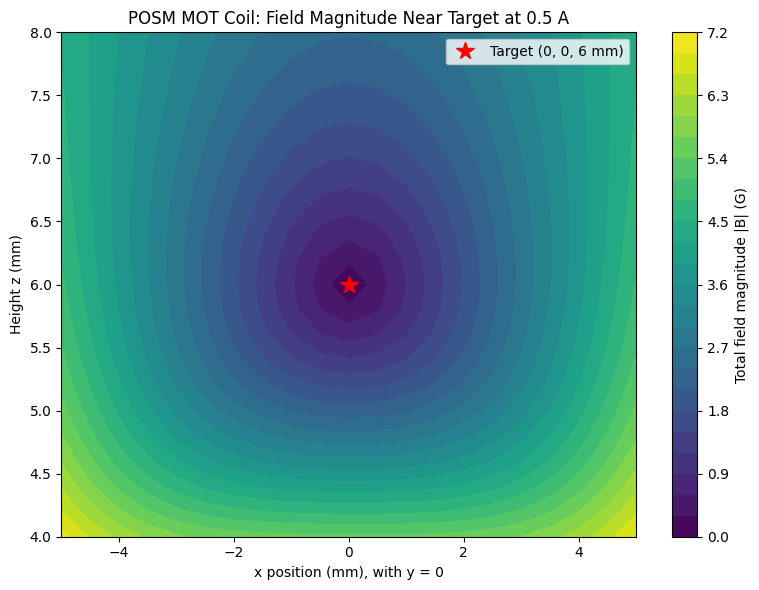

At (0, 0, 6 mm), current = 0.50 A:
Bx = -0.017137 G
By = -0.000441 G
Bz = -0.000580 G
|B| = 0.017153 G
Saved: field_magnitude_near_zero_0p5A.png


In [7]:

from pathlib import Path
import numpy as np
import magpylib as magpy
import matplotlib.pyplot as plt

vertices_file = (
    Path.cwd()
    / "DENSE_06mm_8Cu_7WINDING_LAYERS"
    / "vertices_closed_m.txt"
)
vertices = np.asarray(np.loadtxt(vertices_file)).reshape(-1, 3)

coil = magpy.current.Polyline(current=1.0, vertices=vertices)

current_A = 0.5

# Small region around the target point (0, 0, 6 mm)
x_mm = np.linspace(-5, 5, 21)
z_mm = np.linspace(4, 8, 21)
X, Z = np.meshgrid(x_mm, z_mm)

points = np.column_stack([
    X.ravel() / 1000,
    np.zeros(X.size),
    Z.ravel() / 1000
])

print("Calculating field near the target...")
B = np.asarray(coil.getB(points)).reshape(-1, 3) * current_A
B_G = B * 1e4  # tesla to gauss

Bx = B_G[:, 0].reshape(X.shape)
By = B_G[:, 1].reshape(X.shape)
Bz = B_G[:, 2].reshape(X.shape)
Bmag = np.sqrt(Bx**2 + By**2 + Bz**2)

plt.figure(figsize=(8, 6))
contour = plt.contourf(X, Z, Bmag, levels=25, cmap="viridis")
plt.colorbar(contour, label="Total field magnitude |B| (G)")
plt.plot(0, 6, "r*", markersize=13, label="Target (0, 0, 6 mm)")
plt.xlabel("x position (mm), with y = 0")
plt.ylabel("Height z (mm)")
plt.title("POSM MOT Coil: Field Magnitude Near Target at 0.5 A")
plt.legend()
plt.tight_layout()
plt.savefig("field_magnitude_near_zero_0p5A.png", dpi=200)
plt.show()

# Report field components at the target point
B_target = np.asarray(
    coil.getB(np.array([[0, 0, 0.006]]))
).reshape(3) * current_A * 1e4

print(f"At (0, 0, 6 mm), current = {current_A:.2f} A:")
print(f"Bx = {B_target[0]:.6f} G")
print(f"By = {B_target[1]:.6f} G")
print(f"Bz = {B_target[2]:.6f} G")
print(f"|B| = {np.linalg.norm(B_target):.6f} G")
print("Saved: field_magnitude_near_zero_0p5A.png")


In [8]:

from pathlib import Path

root = Path.cwd()
print("Project folder:", root)

for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".txt", ".csv", ".md", ".py"}:
        name = p.name.lower()
        if any(word in name for word in ["resistance", "summary", "result", "coil", "verify"]):
            print(p.relative_to(root))


Project folder: /Users/naimahughley/Desktop/POSM_CoilPCB/POSM_6mm_Magpylib_Verification_Package/field_simulation
verify_magpylib_6mm.py
.venv/lib/python3.9/site-packages/pyparsing/results.py
.venv/lib/python3.9/site-packages/scipy/ndimage/tests/data/label_results.txt
.venv/lib/python3.9/site-packages/scipy/signal/tests/test_result_type.py
.venv/lib/python3.9/site-packages/scipy/stats/_result_classes.py
.venv/lib/python3.9/site-packages/scipy/stats/tests/data/fisher_exact_results_from_r.py


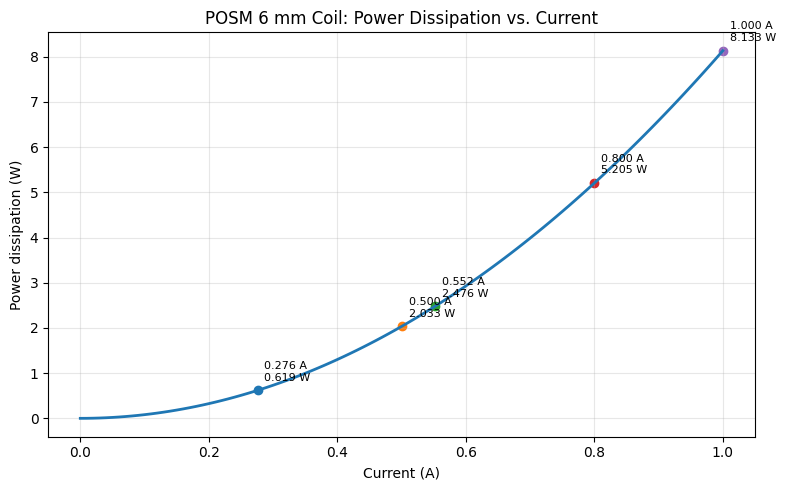

Resistance used: 8.13324 ohms

Current (A) | Power (W)
     0.2759 |    0.6190
     0.5000 |    2.0333
     0.5517 |    2.4758
     0.8000 |    5.2053
     1.0000 |    8.1332

Saved: coil_power_vs_current.png


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Resistance from your 6 mm coil parameter data
R_ohm = 8.133240236055494

currents_A = np.linspace(0, 1.0, 101)
power_W = currents_A**2 * R_ohm

plt.figure(figsize=(8, 5))
plt.plot(currents_A, power_W, linewidth=2)

for I in [0.2758661177464014, 0.5, 0.5517322354928028, 0.8, 1.0]:
    P = I**2 * R_ohm
    plt.scatter(I, P)
    plt.annotate(
        f"{I:.3f} A\n{P:.3f} W",
        (I, P),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Current (A)")
plt.ylabel("Power dissipation (W)")
plt.title("POSM 6 mm Coil: Power Dissipation vs. Current")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("coil_power_vs_current.png", dpi=200)
plt.show()

print(f"Resistance used: {R_ohm:.5f} ohms")
print("\nCurrent (A) | Power (W)")
for I in [0.2758661177464014, 0.5, 0.5517322354928028, 0.8, 1.0]:
    print(f"{I:11.4f} | {I**2 * R_ohm:9.4f}")

print("\nSaved: coil_power_vs_current.png")


In [2]:

from pathlib import Path
import numpy as np

# POSM MOT coil geometry
geometry_file = (
    Path.cwd()
    / "DENSE_06mm_8Cu_7WINDING_LAYERS"
    / "vertices_closed_m.txt"
)

vertices = np.asarray(np.loadtxt(geometry_file), dtype=float)
vertices = vertices.reshape(-1, 3)

# Remove consecutive duplicate points
step_lengths = np.linalg.norm(np.diff(vertices, axis=0), axis=1)
keep = np.r_[True, step_lengths > 1e-12]
vertices = vertices[keep]

# Ensure the current path is closed
if np.linalg.norm(vertices[-1] - vertices[0]) > 1e-12:
    vertices = np.vstack([vertices, vertices[0]])

# Trace geometry
trace_width_m = 0.3e-3
copper_thickness_m = 0.07e-3

print("Geometry file:", geometry_file)
print("Number of vertices:", len(vertices))
print("Total routed path length (m):",
      np.linalg.norm(np.diff(vertices, axis=0), axis=1).sum())
print("Trace width (mm):", trace_width_m * 1000)
print("Copper thickness (mm):", copper_thickness_m * 1000)
print("Path starts at (m):", vertices[0])
print("Path ends at (m):", vertices[-1])


Geometry file: /Users/naimahughley/Desktop/POSM_CoilPCB/POSM_6mm_Magpylib_Verification_Package/field_simulation/DENSE_06mm_8Cu_7WINDING_LAYERS/vertices_closed_m.txt
Number of vertices: 33325
Total routed path length (m): 9.9912210090713
Trace width (mm): 0.3
Copper thickness (mm): 0.06999999999999999
Path starts at (m): [ 0.025    0.0016  -0.00193]
Path ends at (m): [ 0.025    0.0016  -0.00193]


In [3]:

import numpy as np

# Use the vertices variable from your previous cell.
segments = np.diff(vertices, axis=0)
lengths_m = np.linalg.norm(segments, axis=1)
nonzero = lengths_m[lengths_m > 1e-12]

print("=== ROUTED GEOMETRY CHECK ===")
print("X range (mm):",
      np.min(vertices[:, 0]) * 1000,
      "to", np.max(vertices[:, 0]) * 1000)
print("Y range (mm):",
      np.min(vertices[:, 1]) * 1000,
      "to", np.max(vertices[:, 1]) * 1000)
print("Z range (mm):",
      np.min(vertices[:, 2]) * 1000,
      "to", np.max(vertices[:, 2]) * 1000)

print("\nSegment count:", len(lengths_m))
print("Zero-length segments:", np.sum(lengths_m <= 1e-12))
print("Shortest nonzero segment (mm):",
      np.min(nonzero) * 1000)
print("Median segment length (mm):",
      np.median(nonzero) * 1000)
print("Longest segment (mm):",
      np.max(nonzero) * 1000)
print("Sum of segment lengths (m):",
      np.sum(lengths_m))


=== ROUTED GEOMETRY CHECK ===
X range (mm): -19.638554 to 25.0
Y range (mm): -19.146174 to 19.146174
Z range (mm): -1.9300000000000002 to 0.0

Segment count: 33324
Zero-length segments: 0
Shortest nonzero segment (mm): 0.047139878924324606
Median segment length (mm): 0.24688414883404594
Longest segment (mm): 3.700000000000002
Sum of segment lengths (m): 9.9912210090713


In [2]:

import numpy as np
import magpylib as magpy

# ==========================================
# POSM MOT COIL PCB - FIRST GEOMETRY STUDY
# ==========================================

# Mechanical constraints (all dimensions in mm)
inner_diameter_mm = 35.0
outer_diameter_mm = 55.0

inner_radius_mm = inner_diameter_mm / 2
outer_radius_mm = outer_diameter_mm / 2

# Copper trace assumptions
trace_width_mm = 0.30
trace_spacing_mm = 0.30
pitch_mm = trace_width_mm + trace_spacing_mm

# Leave a small margin around the beam opening and outer edge
edge_margin_mm = 0.50

# Adjustable winding counts for the first test
inner_turns = 7
outer_turns = 7

# Opposite current directions for the two winding sections
inner_direction = +1
outer_direction = -1

# Magnetic-field evaluation point
target_height_mm = 6.0
test_current_A = 1.0
target_gradient_G_per_cm = 15.0

# ==========================================
# CHECK THE AVAILABLE RADIAL SPACE
# ==========================================

usable_inner_radius = inner_radius_mm + edge_margin_mm
usable_outer_radius = outer_radius_mm - edge_margin_mm

print("=== MECHANICAL CHECK ===")
print(f"Beam opening: {inner_diameter_mm:.1f} mm")
print(f"PCB outer diameter: {outer_diameter_mm:.1f} mm")
print(f"Available radial winding width: "
      f"{outer_radius_mm - inner_radius_mm:.2f} mm")
print(f"Usable radial range: "
      f"{usable_inner_radius:.2f} to "
      f"{usable_outer_radius:.2f} mm")
print(f"Trace width: {trace_width_mm:.2f} mm")
print(f"Trace spacing assumption: {trace_spacing_mm:.2f} mm")
print(f"Trace pitch: {pitch_mm:.2f} mm")

# Divide the available annulus into two winding bands.
# A 1 mm radial gap is reserved between the bands.
band_gap_mm = 1.0

usable_width = usable_outer_radius - usable_inner_radius
band_width = (usable_width - band_gap_mm) / 2

inner_band_start = usable_inner_radius
inner_band_end = inner_band_start + band_width

outer_band_start = inner_band_end + band_gap_mm
outer_band_end = usable_outer_radius

def make_radii(start_mm, end_mm, turns):
    """Return evenly spaced turn-center radii."""
    if turns < 1:
        raise ValueError("Each winding section needs at least one turn.")

    if turns == 1:
        return np.array([(start_mm + end_mm) / 2])

    return np.linspace(start_mm, end_mm, turns)

inner_radii = make_radii(
    inner_band_start, inner_band_end, inner_turns
)

outer_radii = make_radii(
    outer_band_start, outer_band_end, outer_turns
)

# Check spacing between neighboring turn centerlines.
all_radii = np.sort(np.concatenate([inner_radii, outer_radii]))
radial_pitch = np.diff(all_radii)

print("\n=== WINDING LAYOUT CHECK ===")
print(f"Inner winding band: {inner_band_start:.2f}–"
      f"{inner_band_end:.2f} mm")
print(f"Outer winding band: {outer_band_start:.2f}–"
      f"{outer_band_end:.2f} mm")
print(f"Inner turns: {inner_turns}")
print(f"Outer turns: {outer_turns}")
print(f"Minimum centerline spacing: "
      f"{np.min(radial_pitch):.3f} mm"
      if len(radial_pitch) else "Only one turn")

if len(radial_pitch) and np.min(radial_pitch) < pitch_mm:
    print("WARNING: Turn spacing is smaller than the assumed trace pitch.")
else:
    print("Turn-center spacing passes the preliminary pitch check.")

# ==========================================
# BUILD AN IDEALIZED MAGPYLIB MODEL
# ==========================================

sources = []

for radius in inner_radii:
    sources.append(
        magpy.current.Circle(
            current=inner_direction * test_current_A,
            diameter=2 * radius,
            position=(0, 0, 0),
        )
    )

for radius in outer_radii:
    sources.append(
        magpy.current.Circle(
            current=outer_direction * test_current_A,
            diameter=2 * radius,
            position=(0, 0, 0),
        )
    )

# ==========================================
# CALCULATE AXIAL FIELD AND GRADIENT
# ==========================================


def axial_field_mT(z_mm, current_A):
    # Magpylib 5 uses meters for position and tesla for magnetic field.
    observer = np.array([0.0, 0.0, z_mm * 1e-3])
    total_bz_T = 0.0

    for source in sources:
        field = source.getB(observer)

        # A single observer returns [Bx, By, Bz].
        total_bz_T += field[2] * current_A / test_current_A

    return total_bz_T


dz_mm = 0.05

bz_center = axial_field_mT(target_height_mm, test_current_A)
bz_plus = axial_field_mT(target_height_mm + dz_mm, test_current_A)
bz_minus = axial_field_mT(target_height_mm - dz_mm, test_current_A)

# 1 mT/mm = 100 G/cm
gradient_G_per_cm_per_A = (
    (bz_plus - bz_minus) / (2 * dz_mm) * 100
) / test_current_A

print("\n=== FIELD RESULTS ===")
print(f"Axial field at {target_height_mm:.2f} mm "
      f"at 1 A: {bz_center:.6f} mT")
print(f"Axial gradient at {target_height_mm:.2f} mm "
      f"at 1 A: {gradient_G_per_cm_per_A:.4f} G/cm")

if abs(gradient_G_per_cm_per_A) > 1e-12:
    required_current_A = (
        target_gradient_G_per_cm /
        abs(gradient_G_per_cm_per_A)
    )

    print(f"Current estimated for "
          f"{target_gradient_G_per_cm:.1f} G/cm: "
          f"{required_current_A:.4f} A")

    if required_current_A > 1.0:
        print("NOTE: The target requires more than 1 A in this model.")
else:
    print("Gradient is approximately zero; revise the winding geometry.")

print("\nIMPORTANT:")
print("This is an ideal circular-loop approximation, not a routed PCB.")
print("The field at the target height must also be checked for a zero.")


=== MECHANICAL CHECK ===
Beam opening: 35.0 mm
PCB outer diameter: 55.0 mm
Available radial winding width: 10.00 mm
Usable radial range: 18.00 to 27.00 mm
Trace width: 0.30 mm
Trace spacing assumption: 0.30 mm
Trace pitch: 0.60 mm

=== WINDING LAYOUT CHECK ===
Inner winding band: 18.00–22.00 mm
Outer winding band: 23.00–27.00 mm
Inner turns: 7
Outer turns: 7
Minimum centerline spacing: 0.667 mm
Turn-center spacing passes the preliminary pitch check.

=== FIELD RESULTS ===
Axial field at 6.00 mm at 1 A: 0.000000 mT
Axial gradient at 6.00 mm at 1 A: -0.0000 G/cm
Gradient is approximately zero; revise the winding geometry.

IMPORTANT:
This is an ideal circular-loop approximation, not a routed PCB.
The field at the target height must also be checked for a zero.


=== CORRECTED FIELD CALCULATION ===
Target height: 6.00 mm
Test current: 1.00 A
Axial field Bz: 0.315773 G
Axial gradient: -0.366489 G/cm


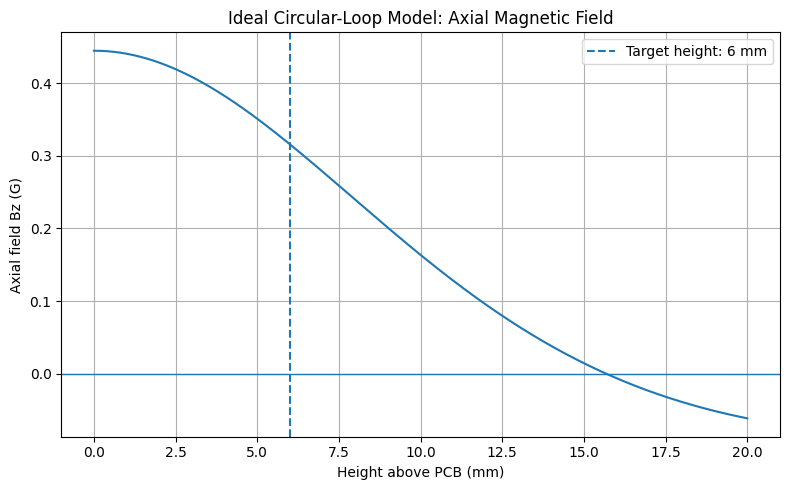

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy

# Magpylib 5 uses SI units:
# positions and diameters in meters; magnetic field in tesla.

test_current_A = 1.0
target_height_mm = 6.0
dz_mm = 0.05

# These radii are assumed to be in mm.
# Convert them to meters when creating the sources.
sources = []

for radius_mm in inner_radii:
    sources.append(
        magpy.current.Circle(
            current=+test_current_A,
            diameter=2 * radius_mm * 1e-3,
            position=(0, 0, 0)
        )
    )

for radius_mm in outer_radii:
    sources.append(
        magpy.current.Circle(
            current=-test_current_A,
            diameter=2 * radius_mm * 1e-3,
            position=(0, 0, 0)
        )
    )


def axial_field_T(z_mm, current_A=1.0):
    """Axial magnetic field Bz in tesla."""
    observer = np.array([0.0, 0.0, z_mm * 1e-3])
    total_bz_T = 0.0

    for source in sources:
        field = source.getB(observer)
        total_bz_T += (
            field[2] * current_A / test_current_A
        )

    return total_bz_T


# Calculate field and numerical axial gradient.
bz_center_T = axial_field_T(target_height_mm, test_current_A)
bz_plus_T = axial_field_T(target_height_mm + dz_mm, test_current_A)
bz_minus_T = axial_field_T(target_height_mm - dz_mm, test_current_A)

# Convert tesla to gauss: 1 T = 10,000 G.
bz_center_G = bz_center_T * 1e4

# dB/dz in T/m, converted to G/cm.
gradient_G_per_cm = (
    (bz_plus_T - bz_minus_T)
    / (2 * dz_mm * 1e-3)
    * 100
)

print("=== CORRECTED FIELD CALCULATION ===")
print(f"Target height: {target_height_mm:.2f} mm")
print(f"Test current: {test_current_A:.2f} A")
print(f"Axial field Bz: {bz_center_G:.6f} G")
print(f"Axial gradient: {gradient_G_per_cm:.6f} G/cm")

# Plot axial field from 0 to 20 mm.
z_values_mm = np.linspace(0, 20, 401)
bz_values_G = np.array([
    axial_field_T(z, test_current_A) * 1e4
    for z in z_values_mm
])

plt.figure(figsize=(8, 5))
plt.plot(z_values_mm, bz_values_G)
plt.axhline(0, linewidth=1)
plt.axvline(target_height_mm, linestyle="--",
            label="Target height: 6 mm")
plt.xlabel("Height above PCB (mm)")
plt.ylabel("Axial field Bz (G)")
plt.title("Ideal Circular-Loop Model: Axial Magnetic Field")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


=== MECHANICAL DESIGN ===
Board diameter: 55.0 mm
Beam opening diameter: 35.0 mm
Inner winding radii: [18.15  18.767 19.383 20.    20.617 21.233 21.85 ] mm
Outer winding radii: [23.15  23.767 24.383 25.    25.617 26.233 26.85 ] mm
Turns per winding: 7
Trace width: 0.30 mm
Nominal trace spacing: 0.30 mm
Test current: 1.00 A

Opening 3D winding visualization...


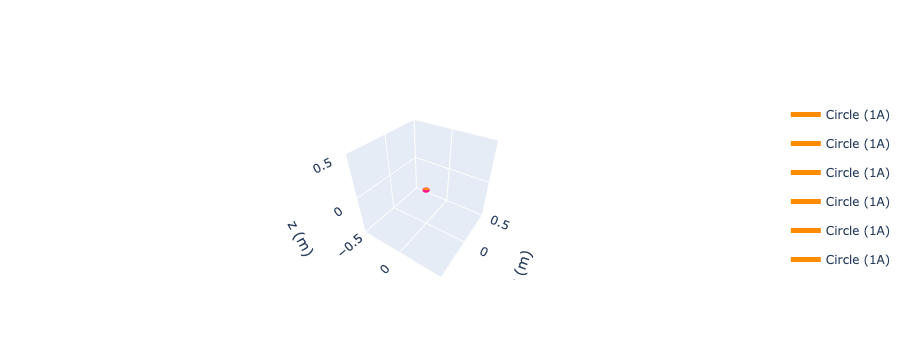


=== AXIAL FIELD RESULTS ===
Zero crossing 1: 15.701 mm above PCB
Axial gradient there: -0.200663 G/cm
Gradient magnitude is outside 10–20 G/cm.

At 6.0 mm:
Bz = 0.315650 G
dBz/dz = -0.365156 G/cm


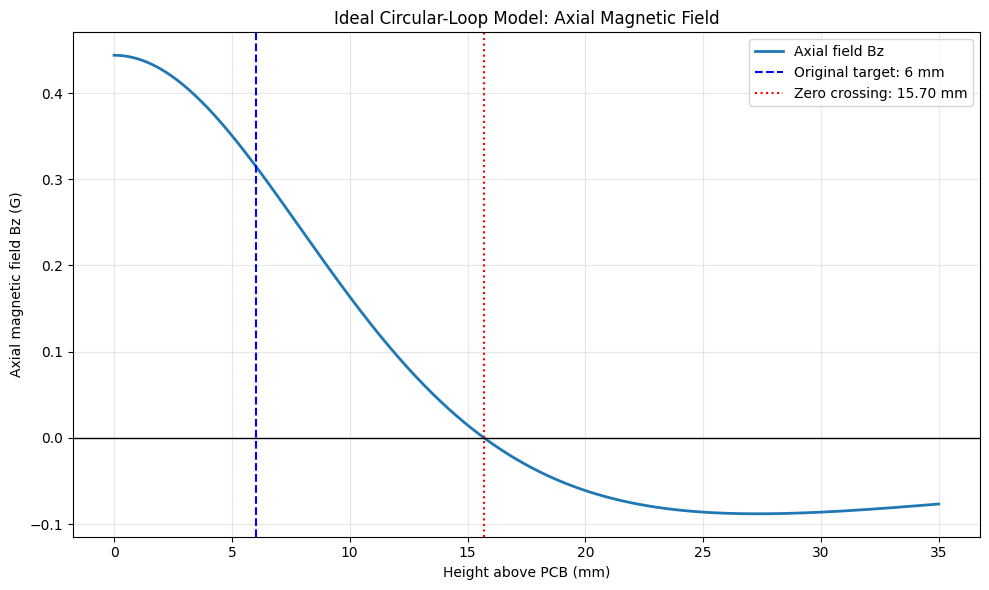

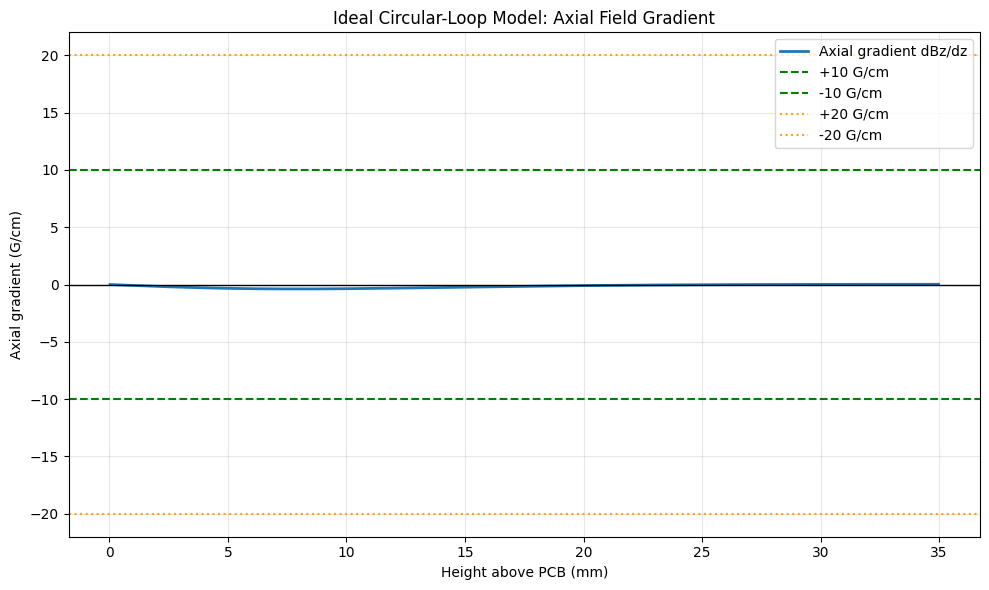

In [4]:

# ============================================================
# POSM MOT COIL PCB — NEW MECHANICAL DESIGN
# Magpylib 3D visualization + axial magnetic-field calculation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy

# Optional: install Plotly in your notebook environment if needed:
# %pip install plotly

# ------------------------------------------------------------
# 1. MECHANICAL DESIGN PARAMETERS
# ------------------------------------------------------------

BOARD_DIAMETER_MM = 55.0
OPENING_DIAMETER_MM = 35.0

INNER_RADIUS_MIN_MM = 18.0
INNER_RADIUS_MAX_MM = 22.0

OUTER_RADIUS_MIN_MM = 23.0
OUTER_RADIUS_MAX_MM = 27.0

TURNS_PER_WINDING = 7
TRACE_WIDTH_MM = 0.30
TRACE_SPACING_MM = 0.30
TRACE_PITCH_MM = TRACE_WIDTH_MM + TRACE_SPACING_MM

CURRENT_A = 1.0

# Ideal loop centerlines, leaving half a trace width
# between the trace edge and each winding-band boundary.
inner_radii = np.linspace(
    INNER_RADIUS_MIN_MM + TRACE_WIDTH_MM / 2,
    INNER_RADIUS_MAX_MM - TRACE_WIDTH_MM / 2,
    TURNS_PER_WINDING
)

outer_radii = np.linspace(
    OUTER_RADIUS_MIN_MM + TRACE_WIDTH_MM / 2,
    OUTER_RADIUS_MAX_MM - TRACE_WIDTH_MM / 2,
    TURNS_PER_WINDING
)

print("=== MECHANICAL DESIGN ===")
print(f"Board diameter: {BOARD_DIAMETER_MM:.1f} mm")
print(f"Beam opening diameter: {OPENING_DIAMETER_MM:.1f} mm")
print(f"Inner winding radii: {inner_radii.round(3)} mm")
print(f"Outer winding radii: {outer_radii.round(3)} mm")
print(f"Turns per winding: {TURNS_PER_WINDING}")
print(f"Trace width: {TRACE_WIDTH_MM:.2f} mm")
print(f"Nominal trace spacing: {TRACE_SPACING_MM:.2f} mm")
print(f"Test current: {CURRENT_A:.2f} A")

# ------------------------------------------------------------
# 2. CREATE IDEAL CIRCULAR CURRENT LOOPS
# ------------------------------------------------------------
# IMPORTANT:
# These are ideal concentric loops, not the exact routed PCB.
# Inner loops carry +I; outer loops carry -I.
# All loops are in the same plane at z = 0.

inner_sources = []
outer_sources = []

for radius_mm in inner_radii:
    coil = magpy.current.Circle(
        current=+CURRENT_A,
        diameter=2 * radius_mm * 1e-3,
        position=(0, 0, 0)
    )
    coil.style.color = "darkorange"
    inner_sources.append(coil)

for radius_mm in outer_radii:
    coil = magpy.current.Circle(
        current=-CURRENT_A,
        diameter=2 * radius_mm * 1e-3,
        position=(0, 0, 0)
    )
    coil.style.color = "deeppink"
    outer_sources.append(coil)

sources = inner_sources + outer_sources

# ------------------------------------------------------------
# 3. 3D VISUALIZATION OF THE WINDINGS
# ------------------------------------------------------------

print("\nOpening 3D winding visualization...")

magpy.show(
    sources,
    backend="plotly"
)

# ------------------------------------------------------------
# 4. CALCULATE AXIAL MAGNETIC FIELD
# ------------------------------------------------------------
# Magpylib uses meters for position and tesla for B.
# Convert results to gauss for reporting.

def axial_field_T(z_mm):
    """Return total axial magnetic field Bz in tesla."""
    observer = np.array([0.0, 0.0, z_mm * 1e-3])

    total_bz_T = 0.0

    for coil in sources:
        field = coil.getB(observer)
        total_bz_T += field[2]

    return total_bz_T


def axial_gradient_G_per_cm(z_mm, step_mm=0.01):
    """Numerically calculate dBz/dz in gauss per centimeter."""
    b_plus = axial_field_T(z_mm + step_mm)
    b_minus = axial_field_T(z_mm - step_mm)

    dz_m = 2 * step_mm * 1e-3

    gradient_T_per_m = (b_plus - b_minus) / dz_m

    # 1 T/m = 100 G/cm
    return gradient_T_per_m * 100


# ------------------------------------------------------------
# 5. FIND AN AXIAL ZERO CROSSING
# ------------------------------------------------------------

z_values_mm = np.linspace(0, 35, 1401)
bz_values_G = np.array([
    axial_field_T(z) * 1e4 for z in z_values_mm
])

zero_points_mm = []

for i in range(len(z_values_mm) - 1):
    b1 = bz_values_G[i]
    b2 = bz_values_G[i + 1]

    if b1 == 0:
        zero_points_mm.append(z_values_mm[i])
    elif b1 * b2 < 0:
        # Linear interpolation between adjacent samples
        z1 = z_values_mm[i]
        z2 = z_values_mm[i + 1]

        z_zero = z1 - b1 * (z2 - z1) / (b2 - b1)
        zero_points_mm.append(z_zero)

print("\n=== AXIAL FIELD RESULTS ===")

if zero_points_mm:
    for index, z_zero in enumerate(zero_points_mm, start=1):
        gradient = axial_gradient_G_per_cm(z_zero)

        print(f"Zero crossing {index}: {z_zero:.3f} mm above PCB")
        print(f"Axial gradient there: {gradient:.6f} G/cm")

        if 10 <= abs(gradient) <= 20:
            print("Gradient magnitude is within 10–20 G/cm.")
        else:
            print("Gradient magnitude is outside 10–20 G/cm.")

        print()
else:
    print("No axial zero crossing found between 0 and 35 mm.")

# Field and gradient at the original 6 mm target
target_height_mm = 6.0

target_bz_G = axial_field_T(target_height_mm) * 1e4
target_gradient = axial_gradient_G_per_cm(target_height_mm)

print(f"At {target_height_mm:.1f} mm:")
print(f"Bz = {target_bz_G:.6f} G")
print(f"dBz/dz = {target_gradient:.6f} G/cm")

# ------------------------------------------------------------
# 6. PLOT AXIAL MAGNETIC FIELD
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    z_values_mm,
    bz_values_G,
    label="Axial field Bz",
    linewidth=2
)

plt.axhline(0, color="black", linewidth=1)

plt.axvline(
    target_height_mm,
    color="blue",
    linestyle="--",
    label=f"Original target: {target_height_mm:g} mm"
)

for z_zero in zero_points_mm:
    plt.axvline(
        z_zero,
        color="red",
        linestyle=":",
        label=f"Zero crossing: {z_zero:.2f} mm"
    )

plt.xlabel("Height above PCB (mm)")
plt.ylabel("Axial magnetic field Bz (G)")
plt.title("Ideal Circular-Loop Model: Axial Magnetic Field")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. PLOT AXIAL GRADIENT
# ------------------------------------------------------------

gradient_values = np.array([
    axial_gradient_G_per_cm(z) for z in z_values_mm[1:-1]
])
gradient_z = z_values_mm[1:-1]

plt.figure(figsize=(10, 6))

plt.plot(
    gradient_z,
    gradient_values,
    label="Axial gradient dBz/dz",
    linewidth=2
)

plt.axhline(10, color="green", linestyle="--", label="+10 G/cm")
plt.axhline(-10, color="green", linestyle="--", label="-10 G/cm")
plt.axhline(20, color="orange", linestyle=":", label="+20 G/cm")
plt.axhline(-20, color="orange", linestyle=":", label="-20 G/cm")
plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Height above PCB (mm)")
plt.ylabel("Axial gradient (G/cm)")
plt.title("Ideal Circular-Loop Model: Axial Field Gradient")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



=== DESIGN PARAMETERS ===
Board OD: 55.0 mm
Opening diameter: 35.0 mm
Inner turns: 7
Outer turns: 7
Trace width: 0.30 mm
Trace spacing: 0.30 mm
Gradient target: 10.0–20.0 G/cm

=== SINGLE-BOARD BASELINE ===
Zero crossing: 15.701 mm
Gradient at zero: -0.2007 G/cm
Gradient magnitude: 0.2007 G/cm
Target met at 1 A: False
Current estimated for 10 G/cm: 49.83 A
Current estimated for 20 G/cm: 99.67 A



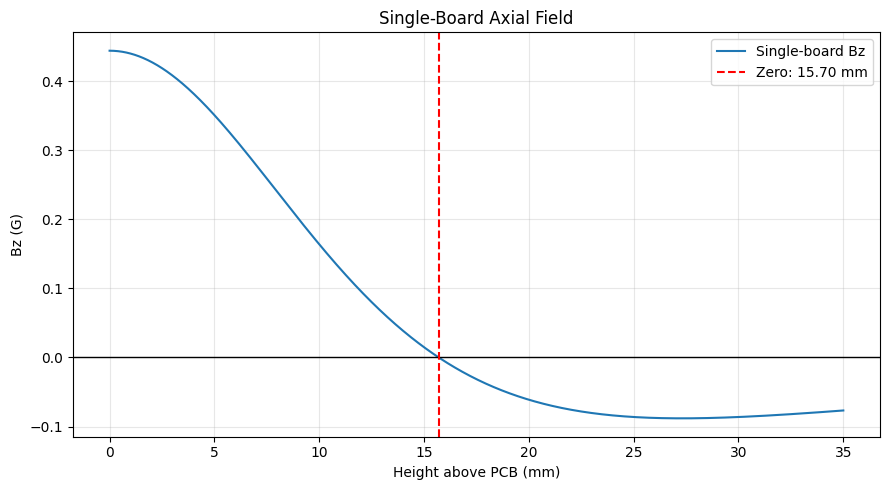

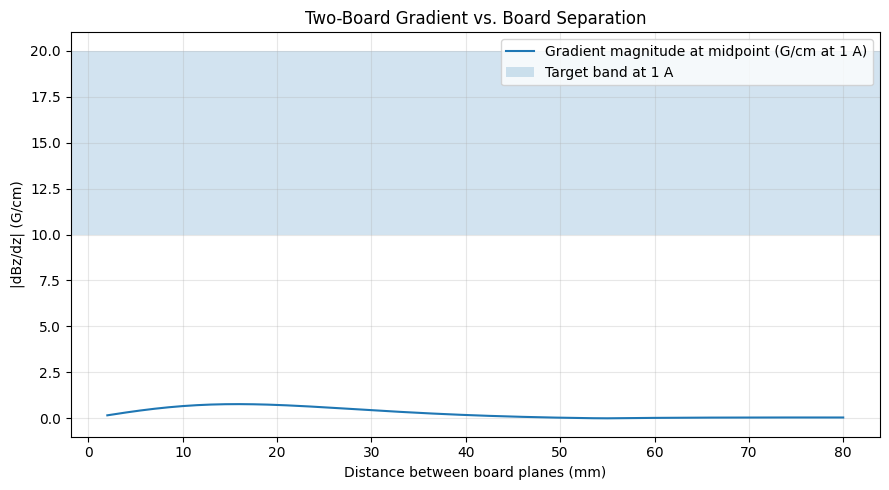

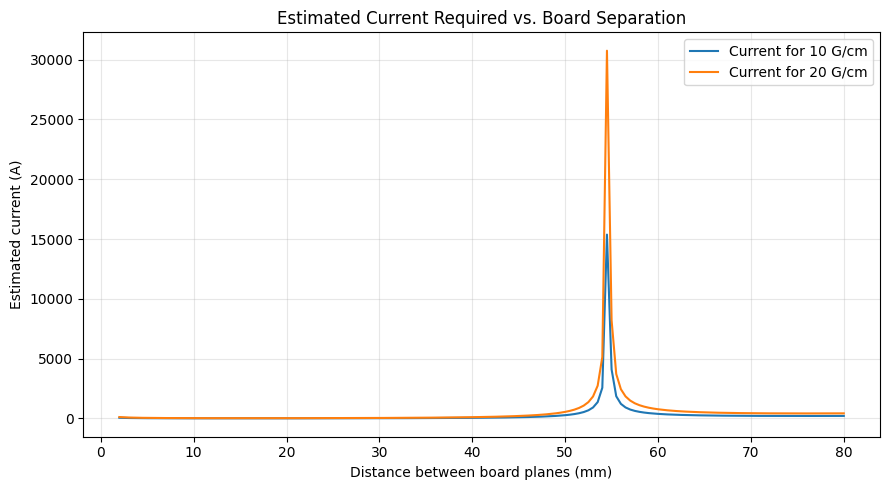


=== TWO-BOARD DESIGN STUDY ===
No tested separation reaches 10–20 G/cm at 1 A.
Highest gradient in this sweep: 0.7739 G/cm
At board separation: 16.00 mm
Estimated current for 10 G/cm at that separation: 12.92 A
Estimated current for 20 G/cm at that separation: 25.84 A

Opening 3D view of the two-board arrangement...


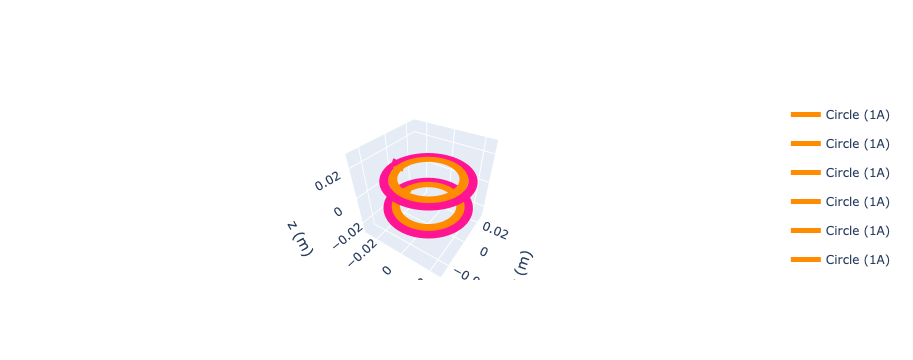

In [5]:

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy

# ============================================================
# POSM MOT COIL PCB — GRADIENT-TARGET DESIGN STUDY
# ============================================================

# Mechanical dimensions
BOARD_DIAMETER_MM = 55.0
OPENING_DIAMETER_MM = 35.0

INNER_RADIUS_MIN_MM = 18.0
INNER_RADIUS_MAX_MM = 22.0
OUTER_RADIUS_MIN_MM = 23.0
OUTER_RADIUS_MAX_MM = 27.0

TURNS_PER_WINDING = 7
TRACE_WIDTH_MM = 0.30
TRACE_SPACING_MM = 0.30

# Magnetic requirements
TARGET_GRADIENT_MIN = 10.0  # G/cm
TARGET_GRADIENT_MAX = 20.0  # G/cm
TEST_CURRENT_A = 1.0

# Model settings
FIELD_STEP_MM = 0.01
Z_PLOT_MAX_MM = 35.0

# ============================================================
# 1. DEFINE IDEAL WINDING CENTERLINES
# ============================================================

inner_radii_mm = np.linspace(
    INNER_RADIUS_MIN_MM + TRACE_WIDTH_MM / 2,
    INNER_RADIUS_MAX_MM - TRACE_WIDTH_MM / 2,
    TURNS_PER_WINDING
)

outer_radii_mm = np.linspace(
    OUTER_RADIUS_MIN_MM + TRACE_WIDTH_MM / 2,
    OUTER_RADIUS_MAX_MM - TRACE_WIDTH_MM / 2,
    TURNS_PER_WINDING
)

# Each board contains 7 inner loops and 7 outer loops.
# Inner and outer groups have opposite current directions.
loop_data = (
    [(r, +1.0, "Inner") for r in inner_radii_mm]
    + [(r, -1.0, "Outer") for r in outer_radii_mm]
)

print("=== DESIGN PARAMETERS ===")
print(f"Board OD: {BOARD_DIAMETER_MM:.1f} mm")
print(f"Opening diameter: {OPENING_DIAMETER_MM:.1f} mm")
print(f"Inner turns: {TURNS_PER_WINDING}")
print(f"Outer turns: {TURNS_PER_WINDING}")
print(f"Trace width: {TRACE_WIDTH_MM:.2f} mm")
print(f"Trace spacing: {TRACE_SPACING_MM:.2f} mm")
print(f"Gradient target: {TARGET_GRADIENT_MIN:.1f}–"
      f"{TARGET_GRADIENT_MAX:.1f} G/cm")

# ============================================================
# 2. CREATE ONE BOARD AT A SPECIFIED Z POSITION
# ============================================================

def make_board(z_position_mm, current_multiplier=1.0):
    """Create ideal circular loops for one PCB plane."""
    board_sources = []

    for radius_mm, winding_sign, winding_name in loop_data:
        coil = magpy.current.Circle(
            current=(
                TEST_CURRENT_A
                * current_multiplier
                * winding_sign
            ),
            diameter=2 * radius_mm * 1e-3,
            position=(0, 0, z_position_mm * 1e-3)
        )

        if winding_name == "Inner":
            coil.style.color = "darkorange"
        else:
            coil.style.color = "deeppink"

        board_sources.append(coil)

    return board_sources


# ============================================================
# 3. FIELD AND GRADIENT FUNCTIONS
# ============================================================

def total_bz_T(sources, z_mm):
    """Return Bz in tesla on the central axis."""
    observer = np.array([0.0, 0.0, z_mm * 1e-3])
    total = 0.0

    for source in sources:
        total += source.getB(observer)[2]

    return total


def gradient_G_per_cm(sources, z_mm, step_mm=FIELD_STEP_MM):
    """Return dBz/dz in G/cm using a central difference."""
    b_plus = total_bz_T(sources, z_mm + step_mm)
    b_minus = total_bz_T(sources, z_mm - step_mm)

    dz_m = 2 * step_mm * 1e-3
    gradient_T_per_m = (b_plus - b_minus) / dz_m

    # 1 T/m = 100 G/cm
    return gradient_T_per_m * 100


# ============================================================
# 4. SINGLE-BOARD BASELINE
# ============================================================

single_board = make_board(z_position_mm=0.0)

# Find zero crossings of Bz above the single board.
z_scan_mm = np.linspace(0, Z_PLOT_MAX_MM, 1401)
single_bz_G = np.array([
    total_bz_T(single_board, z) * 1e4
    for z in z_scan_mm
])

single_zero_points_mm = []

for i in range(len(z_scan_mm) - 1):
    b1 = single_bz_G[i]
    b2 = single_bz_G[i + 1]

    if b1 * b2 < 0:
        z1, z2 = z_scan_mm[i], z_scan_mm[i + 1]
        z_zero = z1 - b1 * (z2 - z1) / (b2 - b1)
        single_zero_points_mm.append(z_zero)

print("\n=== SINGLE-BOARD BASELINE ===")

if single_zero_points_mm:
    for z_zero in single_zero_points_mm:
        g = gradient_G_per_cm(single_board, z_zero)
        print(f"Zero crossing: {z_zero:.3f} mm")
        print(f"Gradient at zero: {g:.4f} G/cm")
        print(f"Gradient magnitude: {abs(g):.4f} G/cm")
        print(f"Target met at 1 A: "
              f"{TARGET_GRADIENT_MIN <= abs(g) <= TARGET_GRADIENT_MAX}")

        if abs(g) > 0:
            print(f"Current estimated for 10 G/cm: "
                  f"{TARGET_GRADIENT_MIN / abs(g):.2f} A")
            print(f"Current estimated for 20 G/cm: "
                  f"{TARGET_GRADIENT_MAX / abs(g):.2f} A")
        print()
else:
    print("No zero crossing found in the scanned height range.")

# Plot the single-board field
plt.figure(figsize=(9, 5))
plt.plot(z_scan_mm, single_bz_G, label="Single-board Bz")
plt.axhline(0, color="black", linewidth=1)

for z_zero in single_zero_points_mm:
    plt.axvline(z_zero, color="red", linestyle="--",
                label=f"Zero: {z_zero:.2f} mm")

plt.xlabel("Height above PCB (mm)")
plt.ylabel("Bz (G)")
plt.title("Single-Board Axial Field")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 5. TWO-BOARD CONFIGURATION STUDY
# ============================================================
# Hypothesis: two identical boards placed symmetrically about
# z=0, with the second board's current directions reversed.
# This is an idealized anti-Helmholtz-style arrangement.
#
# IMPORTANT: The two-board result is a design study, not a
# validated representation of your physical assembly.

separations_mm = np.linspace(2.0, 80.0, 157)

gradient_per_amp = []
required_current_for_10 = []
required_current_for_20 = []

for separation_mm in separations_mm:
    # Lower board carries the defined winding currents.
    lower = make_board(
        z_position_mm=-separation_mm / 2,
        current_multiplier=+1.0
    )

    # Upper board has the overall current direction reversed.
    upper = make_board(
        z_position_mm=+separation_mm / 2,
        current_multiplier=-1.0
    )

    pair_sources = lower + upper

    # Symmetry gives Bz = 0 at the midpoint for this model.
    midpoint_gradient = gradient_G_per_cm(pair_sources, 0.0)

    gradient_per_amp.append(midpoint_gradient)

    g_abs = abs(midpoint_gradient)

    if g_abs > 1e-12:
        required_current_for_10.append(
            TARGET_GRADIENT_MIN / g_abs
        )
        required_current_for_20.append(
            TARGET_GRADIENT_MAX / g_abs
        )
    else:
        required_current_for_10.append(np.nan)
        required_current_for_20.append(np.nan)

gradient_per_amp = np.array(gradient_per_amp)
required_current_for_10 = np.array(required_current_for_10)
required_current_for_20 = np.array(required_current_for_20)

# Plot gradient per amp as a function of separation.
plt.figure(figsize=(9, 5))
plt.plot(
    separations_mm,
    np.abs(gradient_per_amp),
    label="Gradient magnitude at midpoint (G/cm at 1 A)"
)
plt.axhspan(
    TARGET_GRADIENT_MIN,
    TARGET_GRADIENT_MAX,
    alpha=0.2,
    label="Target band at 1 A"
)
plt.xlabel("Distance between board planes (mm)")
plt.ylabel("|dBz/dz| (G/cm)")
plt.title("Two-Board Gradient vs. Board Separation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot the current required to reach the gradient range.
plt.figure(figsize=(9, 5))
plt.plot(
    separations_mm,
    required_current_for_10,
    label="Current for 10 G/cm"
)
plt.plot(
    separations_mm,
    required_current_for_20,
    label="Current for 20 G/cm"
)
plt.xlabel("Distance between board planes (mm)")
plt.ylabel("Estimated current (A)")
plt.title("Estimated Current Required vs. Board Separation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 6. REPORT BEST SEPARATIONS FOR THE TARGET AT 1 A
# ============================================================

target_mask = (
    (np.abs(gradient_per_amp) >= TARGET_GRADIENT_MIN)
    & (np.abs(gradient_per_amp) <= TARGET_GRADIENT_MAX)
)

print("\n=== TWO-BOARD DESIGN STUDY ===")

if np.any(target_mask):
    matching_separations = separations_mm[target_mask]
    print("Separations reaching the target gradient at 1 A:")
    print(
        f"{matching_separations.min():.2f} to "
        f"{matching_separations.max():.2f} mm"
    )
else:
    best_idx = np.argmax(np.abs(gradient_per_amp))
    best_sep = separations_mm[best_idx]
    best_grad = abs(gradient_per_amp[best_idx])

    print("No tested separation reaches 10–20 G/cm at 1 A.")
    print(f"Highest gradient in this sweep: {best_grad:.4f} G/cm")
    print(f"At board separation: {best_sep:.2f} mm")
    if best_grad > 1e-12:
        print(f"Estimated current for 10 G/cm at that separation: "
              f"{TARGET_GRADIENT_MIN / best_grad:.2f} A")
        print(f"Estimated current for 20 G/cm at that separation: "
              f"{TARGET_GRADIENT_MAX / best_grad:.2f} A")

# ============================================================
# 7. INTERACTIVE 3D EXAMPLE OF TWO BOARDS
# ============================================================
# Change this value to inspect a different separation.
DISPLAY_SEPARATION_MM = 20.0

lower_display = make_board(
    -DISPLAY_SEPARATION_MM / 2, current_multiplier=+1.0
)
upper_display = make_board(
    +DISPLAY_SEPARATION_MM / 2, current_multiplier=-1.0
)

print("\nOpening 3D view of the two-board arrangement...")
magpy.show(
    lower_display + upper_display,
    backend="plotly"
)


DESIGN A: ONE PCB, 7 LAYERS
Board OD: 60.0 mm
Central aperture: 35.0 mm
Inner turns: 77
Outer turns: 70
Current used for simulation: 1.00 A

Zero crossing 1: z = -20.788 mm
Gradient there: 1.5515 G/cm
Gradient magnitude: 1.5515 G/cm
Current estimated for 10 G/cm: 6.446 A
Current estimated for 20 G/cm: 12.891 A

Zero crossing 2: z = 20.788 mm
Gradient there: -1.5515 G/cm
Gradient magnitude: 1.5515 G/cm
Current estimated for 10 G/cm: 6.446 A
Current estimated for 20 G/cm: 12.891 A


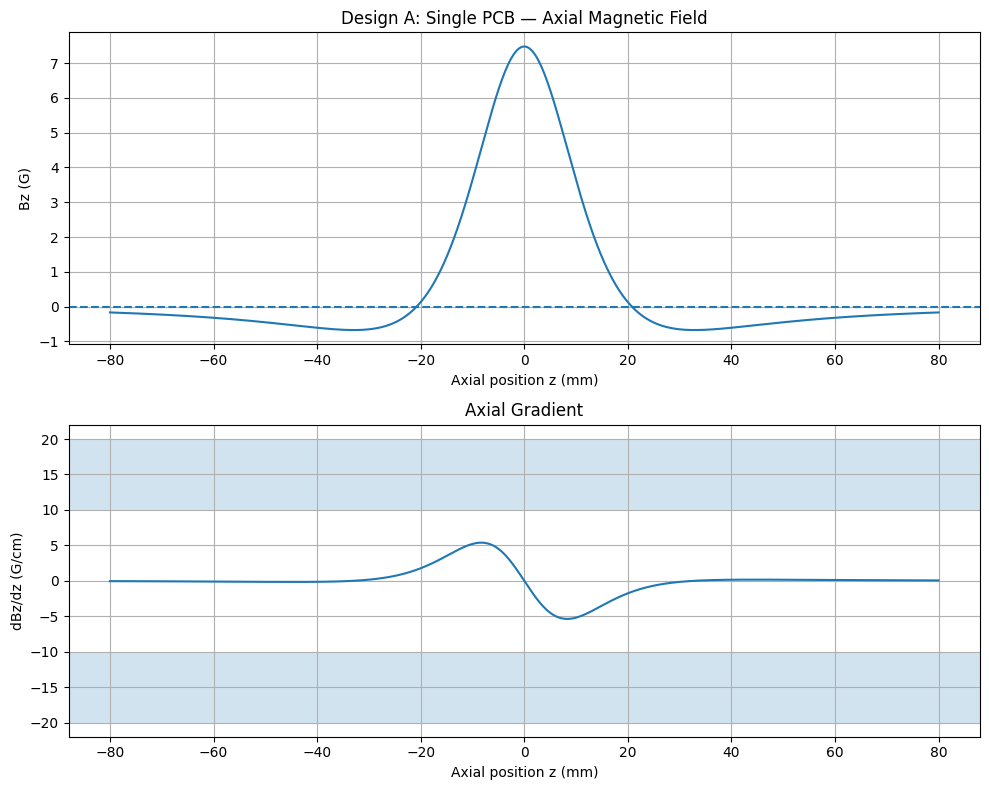


DESIGN B: TWO-BOARD SEPARATION SWEEP
Highest gradient in tested sweep: -10.7600 G/cm
Board center-to-center separation: 16.65 mm
Gradient magnitude: 10.7600 G/cm
Current estimated for 10 G/cm at this spacing: 0.929 A
Current estimated for 20 G/cm at this spacing: 1.859 A


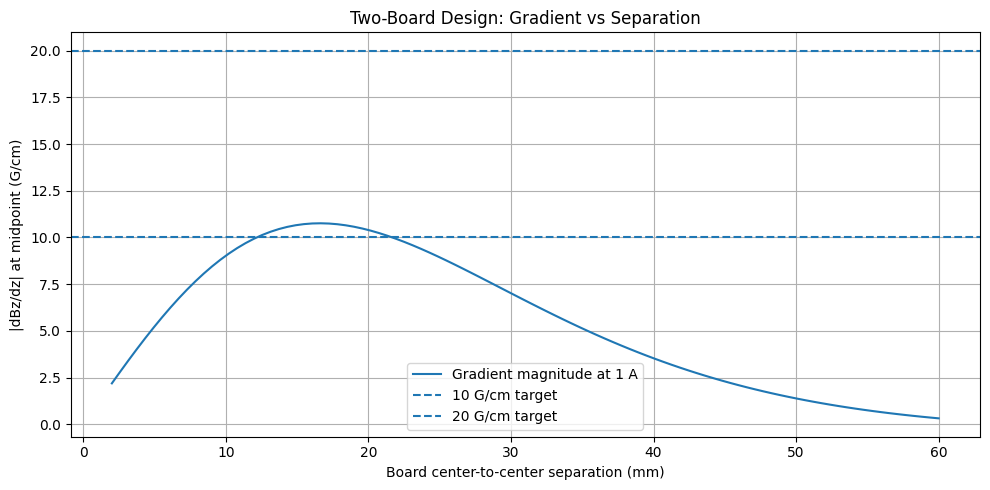

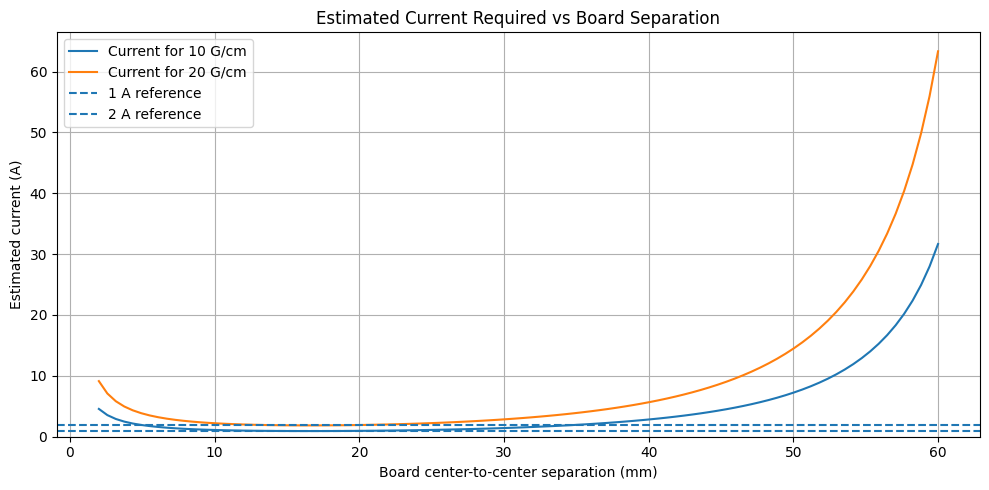


Opening 3D view of one PCB...


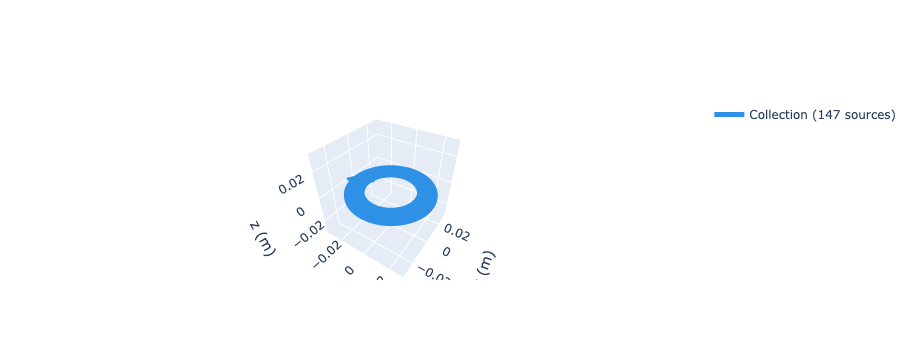


Opening 3D view of the two-board pair...


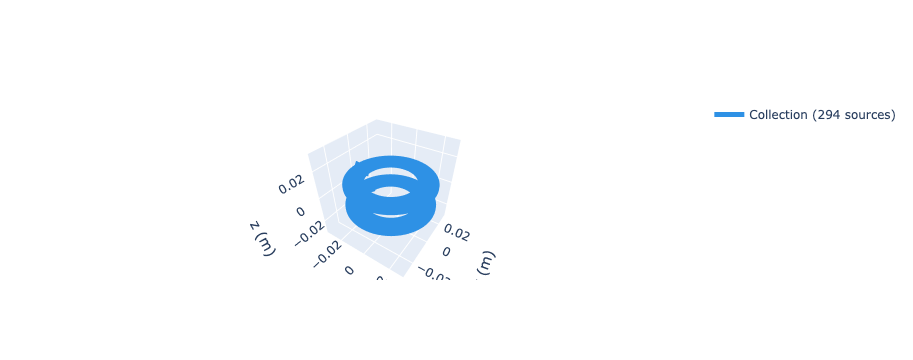

In [6]:

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy

from scipy.optimize import brentq

# ============================================================
# POSM MOT COIL PCB — 7-LAYER PRELIMINARY MODEL
# ============================================================

# ---------- PCB geometry ----------
BOARD_OD_MM = 60.0
APERTURE_DIAMETER_MM = 35.0

INNER_TURNS_PER_LAYER = 11
OUTER_TURNS_PER_LAYER = 10
PCB_LAYERS = 7

INNER_RADIUS_MIN_MM = 18.0
INNER_RADIUS_MAX_MM = 22.0
OUTER_RADIUS_MIN_MM = 23.0
OUTER_RADIUS_MAX_MM = 29.7

# Approximate copper-layer spacing.
# Replace with the actual layer stackup when available.
LAYER_SPACING_MM = 0.20

# Coil current to test
TEST_CURRENT_A = 1.0

# Two-board separation sweep
SEPARATIONS_MM = np.linspace(2, 60, 100)

# Target axial gradient
TARGET_GRADIENTS_G_CM = [10.0, 20.0]

# Numerical field sampling
Z_RANGE_MM = 80
Z_STEP_MM = 0.1


# ============================================================
# BUILD ONE PCB AS INDIVIDUAL CIRCULAR LOOPS
# ============================================================

def make_board(z_center_mm=0.0, current_sign=1.0,
               current_A=1.0):
    """
    Approximate a 7-layer PCB as individual circular current loops.

    Inner winding: 11 turns per layer, 7 layers = 77 loops
    Outer winding: 10 turns per layer, 7 layers = 70 loops

    Inner and outer winding groups have opposite current directions.
    This is an ideal-loop approximation, not routed PCB geometry.
    """

    board = magpy.Collection()

    inner_radii_mm = np.linspace(
        INNER_RADIUS_MIN_MM,
        INNER_RADIUS_MAX_MM,
        INNER_TURNS_PER_LAYER
    )

    outer_radii_mm = np.linspace(
        OUTER_RADIUS_MIN_MM,
        OUTER_RADIUS_MAX_MM,
        OUTER_TURNS_PER_LAYER
    )

    layer_z_offsets_mm = (
        np.arange(PCB_LAYERS) - (PCB_LAYERS - 1) / 2
    ) * LAYER_SPACING_MM

    for layer_z in layer_z_offsets_mm:
        z_position_m = (z_center_mm + layer_z) / 1000.0

        # Inner winding group
        for radius_mm in inner_radii_mm:
            loop = magpy.current.Circle(
                current=current_sign * current_A,
                diameter=2 * radius_mm / 1000.0,
                position=(0, 0, z_position_m)
            )
            board.add(loop)

        # Outer winding group: opposite current direction
        for radius_mm in outer_radii_mm:
            loop = magpy.current.Circle(
                current=-current_sign * current_A,
                diameter=2 * radius_mm / 1000.0,
                position=(0, 0, z_position_m)
            )
            board.add(loop)

    return board


# ============================================================
# FIELD AND GRADIENT FUNCTIONS
# ============================================================

def axial_field_G(board, z_mm):
    """Return axial Bz in gauss at positions z_mm."""
    observers = np.column_stack([
        np.zeros_like(np.atleast_1d(z_mm)),
        np.zeros_like(np.atleast_1d(z_mm)),
        np.atleast_1d(z_mm) / 1000.0
    ])

    field_T = board.getB(observers)
    return field_T[:, 2] * 1e4


def gradient_G_cm(z_mm, Bz_G):
    """Numerical derivative dBz/dz in G/cm."""
    return np.gradient(Bz_G, z_mm / 10.0)


def zero_crossings(z_mm, Bz_G):
    """Find approximate zero crossings by interpolation."""
    roots = []

    for i in range(len(Bz_G) - 1):
        if Bz_G[i] == 0:
            roots.append(z_mm[i])
        elif Bz_G[i] * Bz_G[i + 1] < 0:
            z0 = z_mm[i] - Bz_G[i] * (
                z_mm[i + 1] - z_mm[i]
            ) / (Bz_G[i + 1] - Bz_G[i])
            roots.append(z0)

    return np.array(roots)


def value_at_z(z_query, z_mm, values):
    return np.interp(z_query, z_mm, values)


# ============================================================
# DESIGN A — ONE PCB WITH BOTH WINDING GROUPS
# ============================================================

single_board = make_board(
    z_center_mm=0,
    current_sign=1,
    current_A=TEST_CURRENT_A
)

z_mm = np.arange(-Z_RANGE_MM, Z_RANGE_MM + Z_STEP_MM, Z_STEP_MM)

B_single_G = axial_field_G(single_board, z_mm)
G_single_G_cm = gradient_G_cm(z_mm, B_single_G)
single_zeros = zero_crossings(z_mm, B_single_G)

print("=" * 65)
print("DESIGN A: ONE PCB, 7 LAYERS")
print("=" * 65)
print(f"Board OD: {BOARD_OD_MM:.1f} mm")
print(f"Central aperture: {APERTURE_DIAMETER_MM:.1f} mm")
print(f"Inner turns: {INNER_TURNS_PER_LAYER * PCB_LAYERS}")
print(f"Outer turns: {OUTER_TURNS_PER_LAYER * PCB_LAYERS}")
print(f"Current used for simulation: {TEST_CURRENT_A:.2f} A")

if len(single_zeros) == 0:
    print("No axial zero crossing found in the sampled range.")
else:
    for i, z0 in enumerate(single_zeros, start=1):
        grad0 = value_at_z(z0, z_mm, G_single_G_cm)
        print(f"\nZero crossing {i}: z = {z0:.3f} mm")
        print(f"Gradient there: {grad0:.4f} G/cm")
        print(f"Gradient magnitude: {abs(grad0):.4f} G/cm")

        if abs(grad0) > 1e-12:
            for target in TARGET_GRADIENTS_G_CM:
                estimated_current = (
                    target / abs(grad0) * TEST_CURRENT_A
                )
                print(
                    f"Current estimated for {target:.0f} G/cm: "
                    f"{estimated_current:.3f} A"
                )

# Plot the single-board field and gradient
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(z_mm, B_single_G)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Design A: Single PCB — Axial Magnetic Field")
axes[0].set_xlabel("Axial position z (mm)")
axes[0].set_ylabel("Bz (G)")
axes[0].grid(True)

axes[1].plot(z_mm, G_single_G_cm)
axes[1].axhspan(10, 20, alpha=0.2)
axes[1].axhspan(-20, -10, alpha=0.2)
axes[1].set_title("Axial Gradient")
axes[1].set_xlabel("Axial position z (mm)")
axes[1].set_ylabel("dBz/dz (G/cm)")
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# DESIGN B — TWO BOARDS, OPPOSITE OVERALL CURRENT DIRECTIONS
# ============================================================

two_board_results = []

for separation_mm in SEPARATIONS_MM:
    board_1 = make_board(
        z_center_mm=-separation_mm / 2,
        current_sign=1,
        current_A=TEST_CURRENT_A
    )

    board_2 = make_board(
        z_center_mm=separation_mm / 2,
        current_sign=-1,
        current_A=TEST_CURRENT_A
    )

    pair = magpy.Collection(board_1, board_2)

    # Symmetric pair: evaluate the gradient at the midpoint.
    z_pair_mm = np.array([-0.1, 0.0, 0.1])
    B_pair_G = axial_field_G(pair, z_pair_mm)

    # Central difference: G/cm
    central_gradient = (
        (B_pair_G[2] - B_pair_G[0])
        / ((z_pair_mm[2] - z_pair_mm[0]) / 10.0)
    )

    two_board_results.append(
        (separation_mm, central_gradient)
    )

two_board_results = np.array(two_board_results)

separations = two_board_results[:, 0]
gradients = two_board_results[:, 1]

print("\n" + "=" * 65)
print("DESIGN B: TWO-BOARD SEPARATION SWEEP")
print("=" * 65)

best_index = np.argmax(np.abs(gradients))
best_separation = separations[best_index]
best_gradient = gradients[best_index]

print(f"Highest gradient in tested sweep: {best_gradient:.4f} G/cm")
print(f"Board center-to-center separation: {best_separation:.2f} mm")
print(f"Gradient magnitude: {abs(best_gradient):.4f} G/cm")

if abs(best_gradient) > 1e-12:
    for target in TARGET_GRADIENTS_G_CM:
        print(
            f"Current estimated for {target:.0f} G/cm at this spacing: "
            f"{target / abs(best_gradient) * TEST_CURRENT_A:.3f} A"
        )

plt.figure(figsize=(10, 5))
plt.plot(separations, np.abs(gradients), label="Gradient magnitude at 1 A")
plt.axhline(10, linestyle="--", label="10 G/cm target")
plt.axhline(20, linestyle="--", label="20 G/cm target")
plt.xlabel("Board center-to-center separation (mm)")
plt.ylabel("|dBz/dz| at midpoint (G/cm)")
plt.title("Two-Board Design: Gradient vs Separation")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Estimate current required at each spacing, assuming linear field scaling.
plt.figure(figsize=(10, 5))

for target in TARGET_GRADIENTS_G_CM:
    required_current = np.divide(
        target,
        np.abs(gradients),
        out=np.full_like(gradients, np.nan),
        where=np.abs(gradients) > 1e-12
    )
    plt.plot(
        separations,
        required_current,
        label=f"Current for {target:.0f} G/cm"
    )

plt.axhline(1, linestyle="--", label="1 A reference")
plt.axhline(2, linestyle="--", label="2 A reference")
plt.xlabel("Board center-to-center separation (mm)")
plt.ylabel("Estimated current (A)")
plt.title("Estimated Current Required vs Board Separation")
plt.ylim(bottom=0)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3D VISUALIZATION
# ============================================================

try:
    print("\nOpening 3D view of one PCB...")
    magpy.show(single_board, backend="plotly")

    print("\nOpening 3D view of the two-board pair...")
    board_1 = make_board(
        z_center_mm=-best_separation / 2,
        current_sign=1,
        current_A=TEST_CURRENT_A
    )
    board_2 = make_board(
        z_center_mm=best_separation / 2,
        current_sign=-1,
        current_A=TEST_CURRENT_A
    )
    magpy.show(
        magpy.Collection(board_1, board_2),
        backend="plotly"
    )

except Exception as exc:
    print("3D viewer could not open:", exc)
    print("The field plots and numerical results above should still work.")


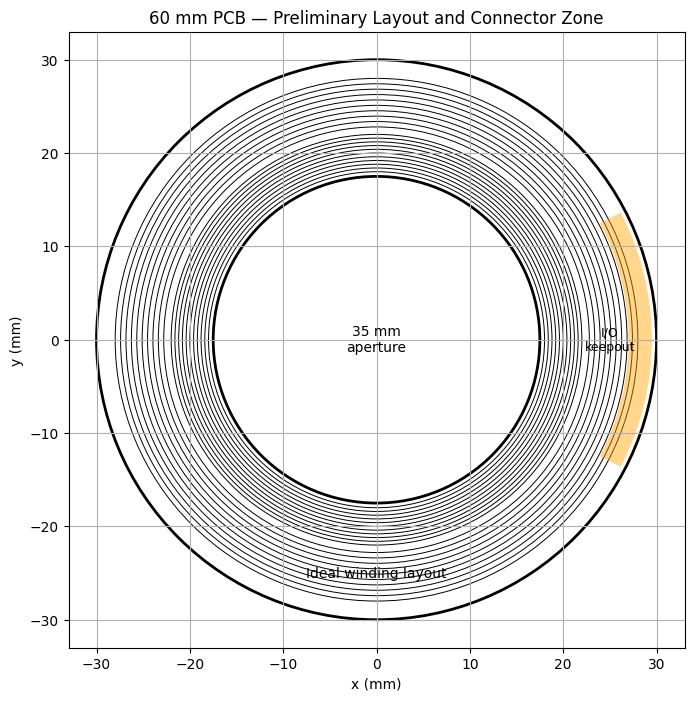

DESIGN A — SINGLE PCB
Board OD: 60.0 mm
Center aperture: 35.0 mm
Inner turn-equivalents: 77
Outer turn-equivalents: 70
Outer winding maximum radius: 28.0 mm
Radial clearance from winding to board edge: 2.0 mm
Test current: 1.00 A

Zero crossing: -21.073 mm
Gradient: 1.3134 G/cm
Estimated current for 10 G/cm: 7.614 A
Estimated current for 20 G/cm: 15.228 A

Zero crossing: 21.073 mm
Gradient: -1.3134 G/cm
Estimated current for 10 G/cm: 7.614 A
Estimated current for 20 G/cm: 15.228 A


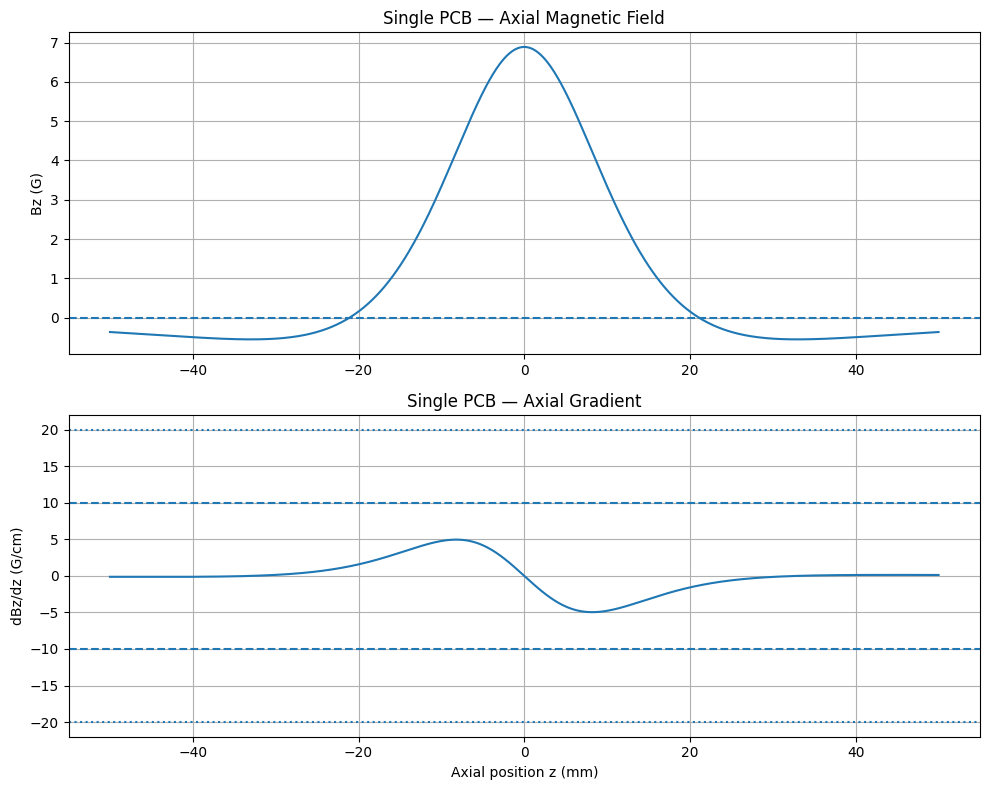


DESIGN B — TWO-BOARD SEPARATION SWEEP
Best tested center-to-center separation: 16.36 mm
Gradient at 1.00 A: -9.9228 G/cm
Gradient magnitude: 9.9228 G/cm
Estimated current for 10 G/cm: 1.008 A
Estimated current for 20 G/cm: 2.016 A


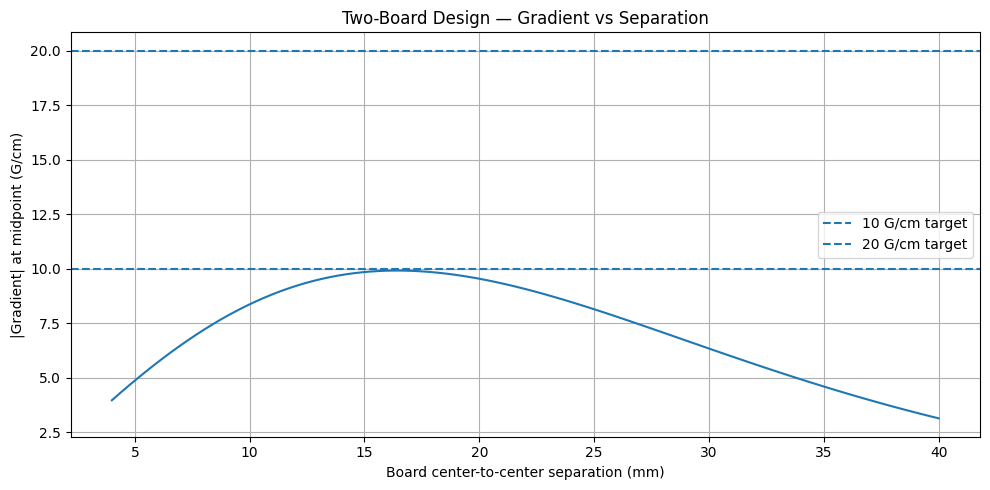

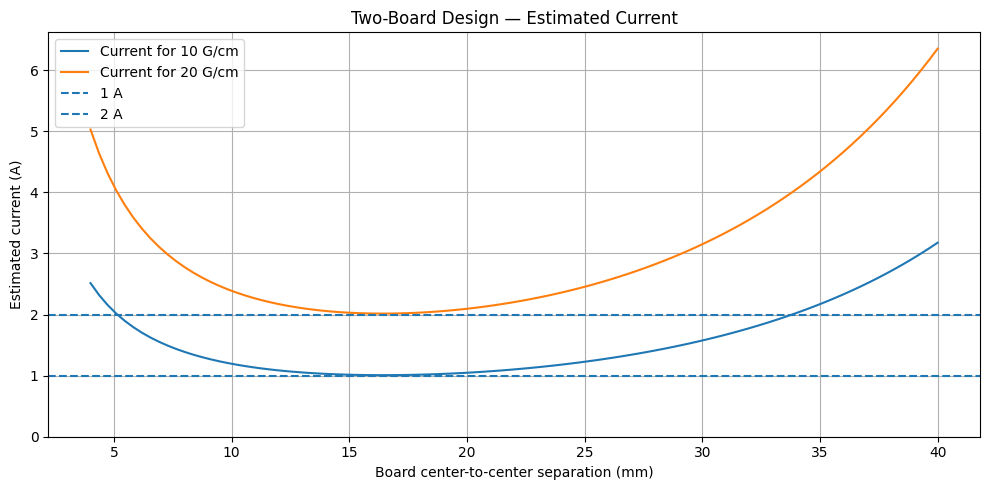


Opening 3D ideal-loop model...


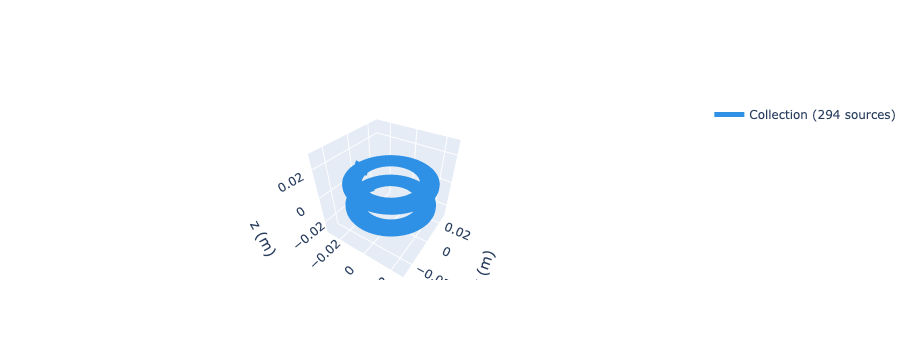

In [7]:

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy
from matplotlib.patches import Circle, Wedge, Rectangle

# ============================================================
# POSM MOT COIL PCB — 60 mm OD, 35 mm APERTURE
# 7-layer ideal-loop magnetic-field model
# ============================================================

# Mechanical dimensions (mm)
BOARD_OD = 60.0
BOARD_R = BOARD_OD / 2
APERTURE_D = 35.0
APERTURE_R = APERTURE_D / 2

# Copper winding counts
LAYERS = 7
INNER_TURNS_PER_LAYER = 11
OUTER_TURNS_PER_LAYER = 10
INNER_TOTAL = LAYERS * INNER_TURNS_PER_LAYER  # 77
OUTER_TOTAL = LAYERS * OUTER_TURNS_PER_LAYER  # 70

# Winding radii (mm)
# Outer winding is moved inward from the previous 29.7 mm limit.
INNER_R_MIN, INNER_R_MAX = 18.0, 22.0
OUTER_R_MIN, OUTER_R_MAX = 22.8, 28.0

# Approximate stackup; replace with actual PCB layer coordinates
LAYER_SPACING_MM = 0.20

# Connector keepout area on the right-hand side of the PCB
# This is a mechanical layout placeholder, not a modeled connector.
CONNECTOR_ANGLE_DEG = 0
CONNECTOR_SECTOR_DEG = 55
CONNECTOR_RADIAL_INNER_MM = 27.0
CONNECTOR_RADIAL_OUTER_MM = 29.5

# Simulation
TEST_CURRENT_A = 1.0
Z_MIN_MM, Z_MAX_MM, Z_STEP_MM = -50, 50, 0.1
SEPARATIONS_MM = np.linspace(4, 40, 100)
TARGETS_G_CM = [10, 20]


# ============================================================
# BUILD IDEAL PCB WINDING
# ============================================================

def make_board(z_center_mm=0, current_sign=1, current_A=1.0):
    """
    Ideal circular-loop approximation.

    Inner loops and outer loops have opposite current directions.
    Each of the 7 layers contains 11 inner and 10 outer loops.

    IMPORTANT:
    Complete circles are used for magnetic calculations.
    The connector keepout is shown in the layout drawing below,
    but its interrupted traces and feed routing are not modeled.
    """

    board = magpy.Collection()

    inner_radii = np.linspace(
        INNER_R_MIN, INNER_R_MAX, INNER_TURNS_PER_LAYER
    )
    outer_radii = np.linspace(
        OUTER_R_MIN, OUTER_R_MAX, OUTER_TURNS_PER_LAYER
    )

    layer_offsets = (
        np.arange(LAYERS) - (LAYERS - 1) / 2
    ) * LAYER_SPACING_MM

    for layer_z in layer_offsets:
        z_m = (z_center_mm + layer_z) / 1000

        for radius_mm in inner_radii:
            board.add(magpy.current.Circle(
                current=current_sign * current_A,
                diameter=2 * radius_mm / 1000,
                position=(0, 0, z_m)
            ))

        for radius_mm in outer_radii:
            board.add(magpy.current.Circle(
                current=-current_sign * current_A,
                diameter=2 * radius_mm / 1000,
                position=(0, 0, z_m)
            ))

    return board


# ============================================================
# AXIAL FIELD / GRADIENT HELPERS
# ============================================================

def axial_field_G(board, z_mm):
    z_mm = np.atleast_1d(z_mm)

    observers = np.column_stack((
        np.zeros_like(z_mm),
        np.zeros_like(z_mm),
        z_mm / 1000
    ))

    B_T = board.getB(observers)
    return B_T[:, 2] * 1e4  # tesla to gauss


def find_zero_crossings(z_mm, B_G):
    roots = []

    for i in range(len(B_G) - 1):
        if B_G[i] == 0:
            roots.append(z_mm[i])
        elif B_G[i] * B_G[i + 1] < 0:
            z0 = z_mm[i] - B_G[i] * (
                z_mm[i + 1] - z_mm[i]
            ) / (B_G[i + 1] - B_G[i])
            roots.append(z0)

    return np.array(roots)


def interp_at(x, x_data, y_data):
    return np.interp(x, x_data, y_data)


# ============================================================
# 2D PCB LAYOUT SKETCH
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))

ax.add_patch(Circle((0, 0), BOARD_R, fill=False, linewidth=2))
ax.add_patch(Circle((0, 0), APERTURE_R, fill=False, linewidth=2))

# Ideal winding rings for visualizing the planned radius bands
for r in np.linspace(INNER_R_MIN, INNER_R_MAX,
                     INNER_TURNS_PER_LAYER):
    ax.add_patch(Circle((0, 0), r, fill=False, linewidth=0.7))

for r in np.linspace(OUTER_R_MIN, OUTER_R_MAX,
                     OUTER_TURNS_PER_LAYER):
    ax.add_patch(Circle((0, 0), r, fill=False, linewidth=0.7))

# Connector keepout sector, drawn near the outer perimeter
half_sector = CONNECTOR_SECTOR_DEG / 2
ax.add_patch(Wedge(
    (0, 0),
    CONNECTOR_RADIAL_OUTER_MM,
    CONNECTOR_ANGLE_DEG - half_sector,
    CONNECTOR_ANGLE_DEG + half_sector,
    width=(CONNECTOR_RADIAL_OUTER_MM -
           CONNECTOR_RADIAL_INNER_MM),
    facecolor="orange",
    alpha=0.45
))

ax.text(0, 0, "35 mm\naperture", ha="center", va="center")
ax.text(0, -25, "Ideal winding layout", ha="center", va="center")
ax.text(25, 0, "I/O\nkeepout", ha="center", va="center",
        fontsize=9)

ax.set_aspect("equal")
ax.set_xlim(-33, 33)
ax.set_ylim(-33, 33)
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_title("60 mm PCB — Preliminary Layout and Connector Zone")
ax.grid(True)
plt.show()


# ============================================================
# DESIGN A — SINGLE PCB
# ============================================================

z_mm = np.arange(Z_MIN_MM, Z_MAX_MM + Z_STEP_MM, Z_STEP_MM)

single = make_board(
    z_center_mm=0,
    current_sign=1,
    current_A=TEST_CURRENT_A
)

B_single = axial_field_G(single, z_mm)
G_single = np.gradient(B_single, z_mm / 10)  # G/cm
zeros = find_zero_crossings(z_mm, B_single)

print("=" * 60)
print("DESIGN A — SINGLE PCB")
print("=" * 60)
print(f"Board OD: {BOARD_OD:.1f} mm")
print(f"Center aperture: {APERTURE_D:.1f} mm")
print(f"Inner turn-equivalents: {INNER_TOTAL}")
print(f"Outer turn-equivalents: {OUTER_TOTAL}")
print(f"Outer winding maximum radius: {OUTER_R_MAX:.1f} mm")
print(f"Radial clearance from winding to board edge: "
      f"{BOARD_R - OUTER_R_MAX:.1f} mm")
print(f"Test current: {TEST_CURRENT_A:.2f} A")

if len(zeros) == 0:
    print("No axial zero crossing found in this range.")
else:
    for z0 in zeros:
        gradient = interp_at(z0, z_mm, G_single)
        print(f"\nZero crossing: {z0:.3f} mm")
        print(f"Gradient: {gradient:.4f} G/cm")

        if abs(gradient) > 1e-12:
            for target in TARGETS_G_CM:
                current_needed = target / abs(gradient)
                print(
                    f"Estimated current for {target} G/cm: "
                    f"{current_needed:.3f} A"
                )

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

ax[0].plot(z_mm, B_single)
ax[0].axhline(0, linestyle="--")
ax[0].set_ylabel("Bz (G)")
ax[0].set_title("Single PCB — Axial Magnetic Field")
ax[0].grid(True)

ax[1].plot(z_mm, G_single)
ax[1].axhline(10, linestyle="--")
ax[1].axhline(-10, linestyle="--")
ax[1].axhline(20, linestyle=":")
ax[1].axhline(-20, linestyle=":")
ax[1].set_xlabel("Axial position z (mm)")
ax[1].set_ylabel("dBz/dz (G/cm)")
ax[1].set_title("Single PCB — Axial Gradient")
ax[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# DESIGN B — TWO BOARDS WITH OPPOSITE OVERALL CURRENTS
# ============================================================

pair_results = []

for separation in SEPARATIONS_MM:
    board_1 = make_board(
        z_center_mm=-separation / 2,
        current_sign=1,
        current_A=TEST_CURRENT_A
    )
    board_2 = make_board(
        z_center_mm=separation / 2,
        current_sign=-1,
        current_A=TEST_CURRENT_A
    )

    pair = magpy.Collection(board_1, board_2)

    # Symmetric arrangement: central field zero at z=0
    z_probe = np.array([-0.1, 0.1])
    B_probe = axial_field_G(pair, z_probe)

    gradient_center = (
        (B_probe[1] - B_probe[0]) /
        ((z_probe[1] - z_probe[0]) / 10)
    )

    pair_results.append((separation, gradient_center))

pair_results = np.array(pair_results)
separations = pair_results[:, 0]
gradients = pair_results[:, 1]
abs_gradients = np.abs(gradients)

best_idx = np.argmax(abs_gradients)
best_sep = separations[best_idx]
best_gradient = gradients[best_idx]

print("\n" + "=" * 60)
print("DESIGN B — TWO-BOARD SEPARATION SWEEP")
print("=" * 60)
print(f"Best tested center-to-center separation: {best_sep:.2f} mm")
print(f"Gradient at {TEST_CURRENT_A:.2f} A: "
      f"{best_gradient:.4f} G/cm")
print(f"Gradient magnitude: {abs(best_gradient):.4f} G/cm")

for target in TARGETS_G_CM:
    if abs(best_gradient) > 1e-12:
        print(
            f"Estimated current for {target} G/cm: "
            f"{target / abs(best_gradient) * TEST_CURRENT_A:.3f} A"
        )

plt.figure(figsize=(10, 5))
plt.plot(separations, abs_gradients)
plt.axhline(10, linestyle="--", label="10 G/cm target")
plt.axhline(20, linestyle="--", label="20 G/cm target")
plt.xlabel("Board center-to-center separation (mm)")
plt.ylabel("|Gradient| at midpoint (G/cm)")
plt.title("Two-Board Design — Gradient vs Separation")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
for target in TARGETS_G_CM:
    current_required = np.divide(
        target,
        abs_gradients,
        out=np.full_like(abs_gradients, np.nan),
        where=abs_gradients > 1e-12
    )
    plt.plot(
        separations, current_required,
        label=f"Current for {target} G/cm"
    )

plt.axhline(1, linestyle="--", label="1 A")
plt.axhline(2, linestyle="--", label="2 A")
plt.xlabel("Board center-to-center separation (mm)")
plt.ylabel("Estimated current (A)")
plt.title("Two-Board Design — Estimated Current")
plt.ylim(bottom=0)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3D VIEW OF THE TWO-BOARD IDEAL-LOOP MODEL
# ============================================================

board_1 = make_board(
    z_center_mm=-best_sep / 2,
    current_sign=1,
    current_A=TEST_CURRENT_A
)
board_2 = make_board(
    z_center_mm=best_sep / 2,
    current_sign=-1,
    current_A=TEST_CURRENT_A
)

print("\nOpening 3D ideal-loop model...")
magpy.show(magpy.Collection(board_1, board_2), backend="plotly")



60 mm PCB
  Board OD: 60.0 mm
  Aperture diameter: 35.0 mm
  Reserved radial connector zone: 7.0 mm
  Maximum winding center radius: 23.0 mm
  Inner turns: 4 per layer, 28 total turn-equivalents
  Outer turns: 4 per layer, 28 total turn-equivalents
  Inner radius range: (18.0, 20.1) mm
  Outer radius range: (20.6, 22.7) mm
  Outer trace edge: 22.85 mm
  Outer edge clearance: 7.15 mm
  inner_radii_mm nominal center pitch: 0.700 mm
  outer_radii_mm nominal center pitch: 0.700 mm

55 mm PCB
  Board OD: 55.0 mm
  Aperture diameter: 35.0 mm
  Reserved radial connector zone: 7.0 mm
  Maximum winding center radius: 20.5 mm
  Inner turns: 2 per layer, 14 total turn-equivalents
  Outer turns: 2 per layer, 14 total turn-equivalents
  Inner radius range: (18.0, 18.9) mm
  Outer radius range: (19.5, 20.3) mm
  Outer trace edge: 20.45 mm
  Outer edge clearance: 7.05 mm
  inner_radii_mm nominal center pitch: 0.900 mm
  outer_radii_mm nominal center pitch: 0.800 mm

SIMULATION: 60 mm PCB


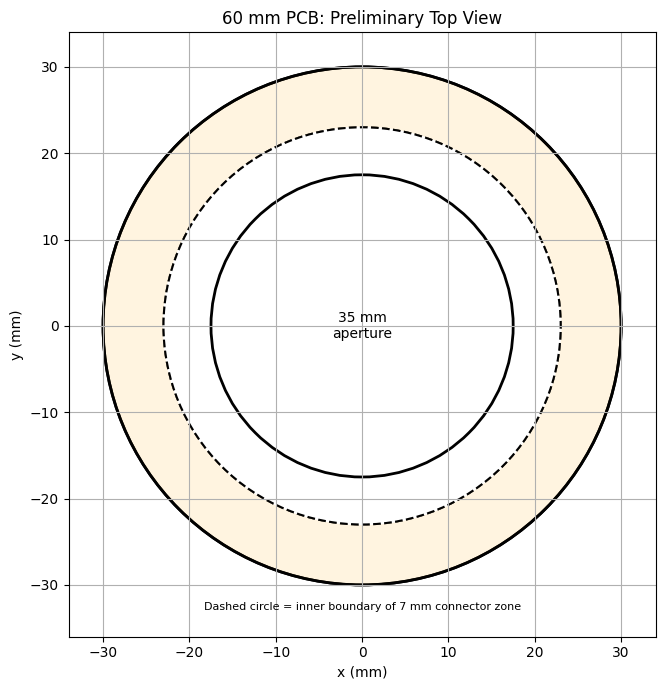


SINGLE PCB
Current: 1.00 A
Zero crossing: -14.328 mm
Gradient there: 0.5591 G/cm
Estimated current for 10.0 G/cm: 17.886 A
Estimated current for 20.0 G/cm: 35.772 A
Zero crossing: 14.328 mm
Gradient there: -0.5591 G/cm
Estimated current for 10.0 G/cm: 17.886 A
Estimated current for 20.0 G/cm: 35.772 A


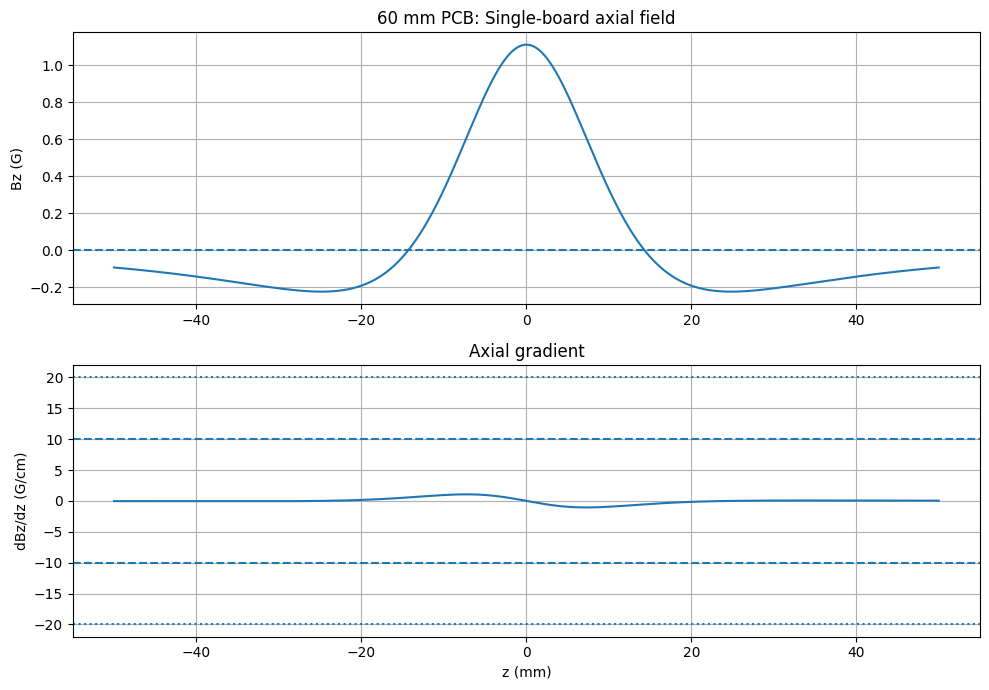


TWO-BOARD PAIR
Best tested separation: 14.50 mm
Gradient at 1.00 A: -2.1222 G/cm
Gradient magnitude: 2.1222 G/cm
Estimated current for 10.0 G/cm: 4.712 A
Estimated current for 20.0 G/cm: 9.424 A


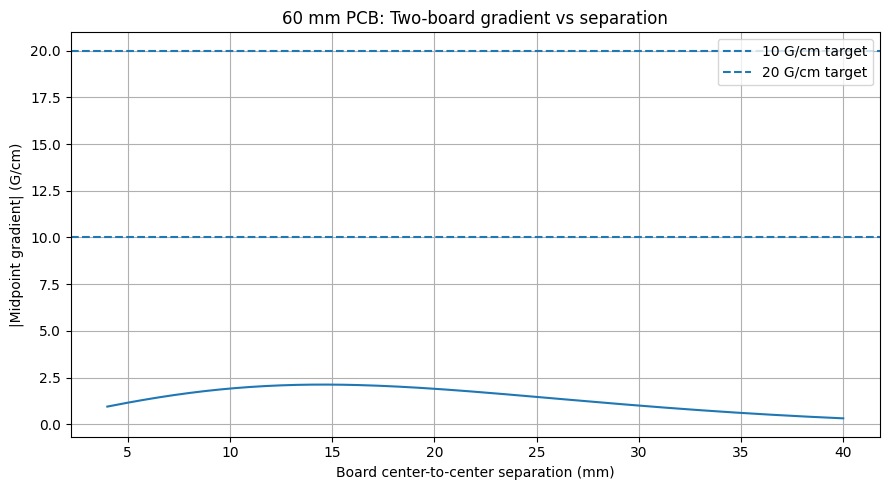

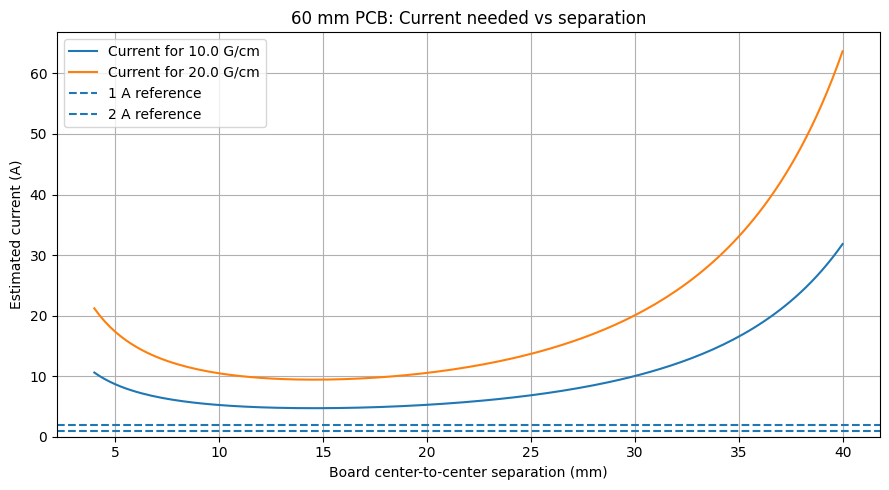


SIMULATION: 55 mm PCB


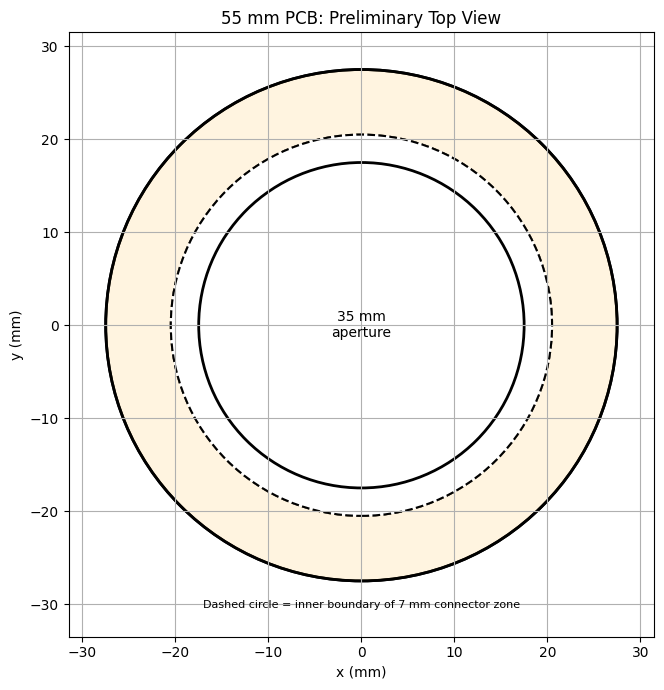


SINGLE PCB
Current: 1.00 A
Zero crossing: -13.538 mm
Gradient there: 0.1861 G/cm
Estimated current for 10.0 G/cm: 53.726 A
Estimated current for 20.0 G/cm: 107.453 A
Zero crossing: 13.538 mm
Gradient there: -0.1861 G/cm
Estimated current for 10.0 G/cm: 53.726 A
Estimated current for 20.0 G/cm: 107.453 A


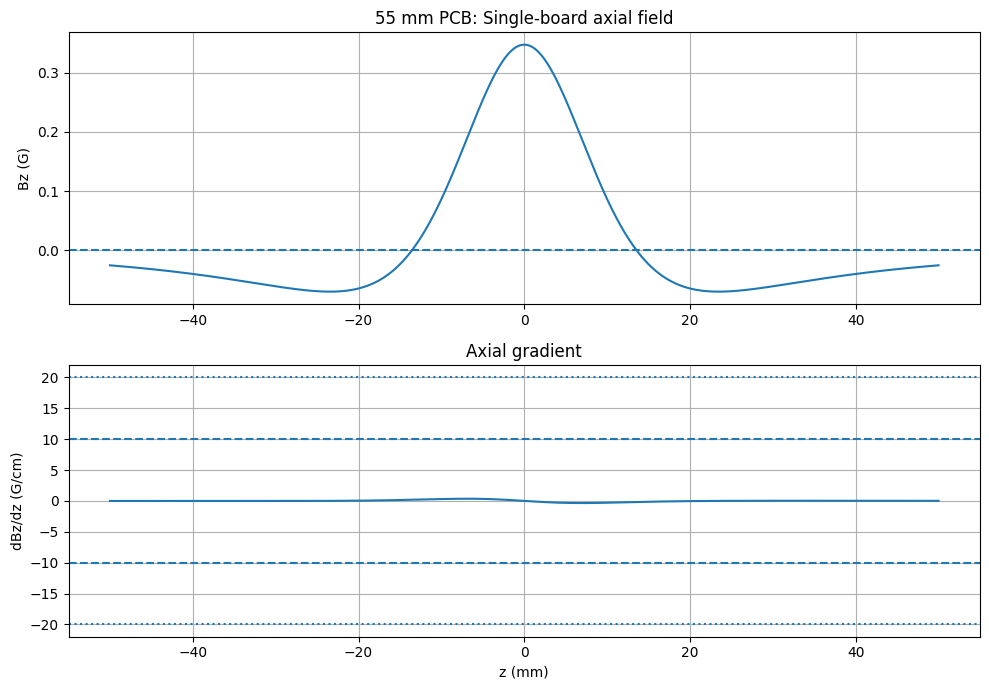


TWO-BOARD PAIR
Best tested separation: 13.75 mm
Gradient at 1.00 A: -0.7020 G/cm
Gradient magnitude: 0.7020 G/cm
Estimated current for 10.0 G/cm: 14.245 A
Estimated current for 20.0 G/cm: 28.491 A


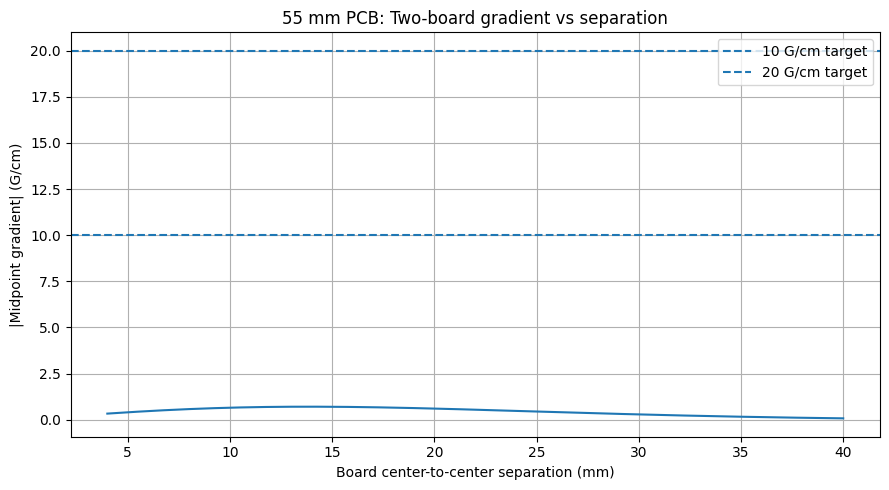

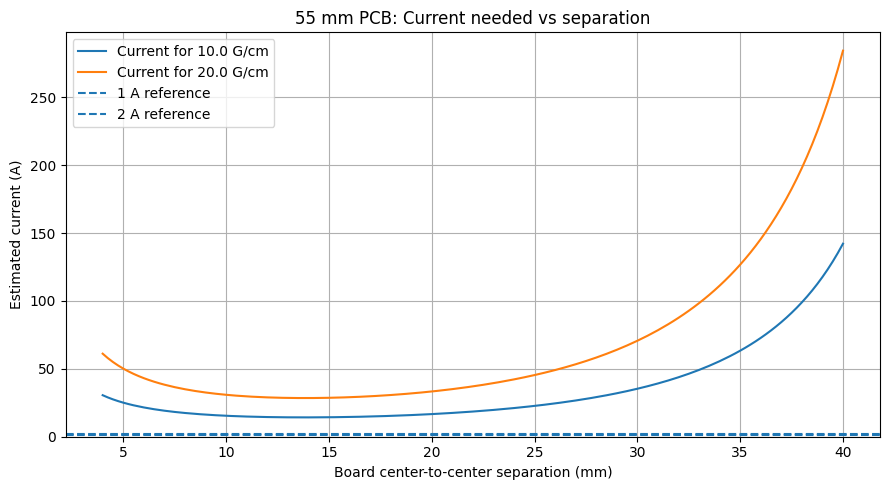


FINAL CANDIDATE COMPARISON

60 mm PCB
  Best tested separation: 14.50 mm
  Gradient magnitude at 1 A: 2.1222 G/cm
  Current estimate for 10.0 G/cm: 4.712 A
  Current estimate for 20.0 G/cm: 9.424 A

55 mm PCB
  Best tested separation: 13.75 mm
  Gradient magnitude at 1 A: 0.7020 G/cm
  Current estimate for 10.0 G/cm: 14.245 A
  Current estimate for 20.0 G/cm: 28.491 A

Opening 3D ideal-loop model: 60 mm PCB


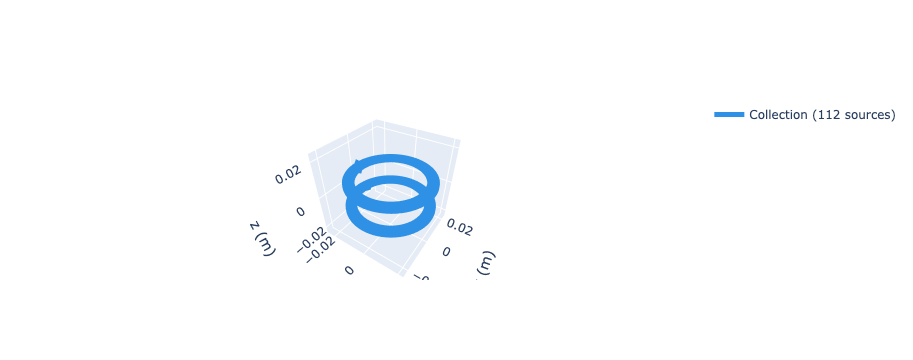

In [9]:

import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy

# ============================================================
# POSM MOT COIL PCB: COMPARE 60 mm AND 55 mm DESIGNS
# Two PCBs per MOT coil system; 7 copper layers per PCB
# ============================================================

# Shared mechanical and electrical parameters
APERTURE_DIAMETER_MM = 35.0
APERTURE_RADIUS_MM = APERTURE_DIAMETER_MM / 2

CONNECTOR_KEEP_OUT_MM = 7.0
LAYERS = 7

TRACE_WIDTH_MM = 0.30
TRACE_SPACING_MM = 0.30
LAYER_SPACING_MM = 0.20  # placeholder; replace with actual stackup

TEST_CURRENT_A = 1.0
TARGET_GRADIENTS_G_CM = [10.0, 20.0]

# Separation means center-to-center distance between boards.
SEPARATIONS_MM = np.linspace(4.0, 40.0, 145)

# Axial field plot range
Z_MIN_MM = -50.0
Z_MAX_MM = 50.0
Z_STEP_MM = 0.1


# ============================================================
# TWO CANDIDATE PCB DESIGNS
# ============================================================

DESIGNS = {
    "60 mm PCB": {
        "board_diameter_mm": 60.0,
        "inner_turns_per_layer": 4,
        "outer_turns_per_layer": 4,
        "inner_radii_mm": (18.0, 20.1),
        "outer_radii_mm": (20.6, 22.7),
    },
    "55 mm PCB": {
        "board_diameter_mm": 55.0,
        "inner_turns_per_layer": 2,
        "outer_turns_per_layer": 2,
        "inner_radii_mm": (18.0, 18.9),
        "outer_radii_mm": (19.5, 20.3),
    },
}


# ============================================================
# GEOMETRY VALIDATION
# ============================================================

def validate_design(name, cfg):
    board_radius = cfg["board_diameter_mm"] / 2
    max_winding_radius = board_radius - CONNECTOR_KEEP_OUT_MM

    for key in ("inner_radii_mm", "outer_radii_mm"):
        rmin, rmax = cfg[key]
        if rmin <= APERTURE_RADIUS_MM:
            raise ValueError(
                f"{name}: {key} overlaps the central aperture."
            )
        if rmax > max_winding_radius:
            raise ValueError(
                f"{name}: {key} enters the 7 mm connector keepout."
            )

    # Check that the outermost copper trace remains within the board.
    outer_trace_edge = cfg["outer_radii_mm"][1] + TRACE_WIDTH_MM / 2
    if outer_trace_edge > max_winding_radius:
        raise ValueError(
            f"{name}: outer trace edge enters the connector keepout."
        )

    print(f"\n{name}")
    print(f"  Board OD: {cfg['board_diameter_mm']:.1f} mm")
    print(f"  Aperture diameter: {APERTURE_DIAMETER_MM:.1f} mm")
    print(f"  Reserved radial connector zone: {CONNECTOR_KEEP_OUT_MM:.1f} mm")
    print(f"  Maximum winding center radius: {max_winding_radius:.1f} mm")
    print(f"  Inner turns: "
          f"{cfg['inner_turns_per_layer']} per layer, "
          f"{cfg['inner_turns_per_layer'] * LAYERS} total turn-equivalents")
    print(f"  Outer turns: "
          f"{cfg['outer_turns_per_layer']} per layer, "
          f"{cfg['outer_turns_per_layer'] * LAYERS} total turn-equivalents")
    print(f"  Inner radius range: {cfg['inner_radii_mm']} mm")
    print(f"  Outer radius range: {cfg['outer_radii_mm']} mm")
    print(f"  Outer trace edge: {outer_trace_edge:.2f} mm")
    print(f"  Outer edge clearance: "
          f"{board_radius - outer_trace_edge:.2f} mm")

    # Informational check of nominal radial pitch.
    for key, count_key in (
        ("inner_radii_mm", "inner_turns_per_layer"),
        ("outer_radii_mm", "outer_turns_per_layer"),
    ):
        count = cfg[count_key]
        rmin, rmax = cfg[key]
        if count > 1:
            pitch = (rmax - rmin) / (count - 1)
            print(f"  {key} nominal center pitch: {pitch:.3f} mm")

for design_name, cfg in DESIGNS.items():
    validate_design(design_name, cfg)


# ============================================================
# BUILD AN IDEAL MULTILAYER PCB
# ============================================================

def make_board(cfg, z_center_mm=0.0, current_sign=1, current_A=1.0):
    """
    Approximate a PCB as circular current loops.

    Each layer has:
      - N inner circular loops
      - N outer circular loops

    Inner and outer groups carry opposite current directions.
    The second board reverses the overall current direction.

    IMPORTANT:
    This is an ideal-loop field model. It does not model the actual
    PCB traces, connector routing, vias, or interrupted windings.
    """

    board = magpy.Collection()

    n_inner = cfg["inner_turns_per_layer"]
    n_outer = cfg["outer_turns_per_layer"]

    inner_radii = np.linspace(
        cfg["inner_radii_mm"][0],
        cfg["inner_radii_mm"][1],
        n_inner
    )
    outer_radii = np.linspace(
        cfg["outer_radii_mm"][0],
        cfg["outer_radii_mm"][1],
        n_outer
    )

    layer_z_offsets = (
        np.arange(LAYERS) - (LAYERS - 1) / 2
    ) * LAYER_SPACING_MM

    for layer_z_mm in layer_z_offsets:
        z_m = (z_center_mm + layer_z_mm) / 1000.0

        # Inner group
        for radius_mm in inner_radii:
            board.add(magpy.current.Circle(
                current=current_sign * current_A,
                diameter=2 * radius_mm / 1000.0,
                position=(0, 0, z_m)
            ))

        # Outer group: opposite current direction
        for radius_mm in outer_radii:
            board.add(magpy.current.Circle(
                current=-current_sign * current_A,
                diameter=2 * radius_mm / 1000.0,
                position=(0, 0, z_m)
            ))

    return board


# ============================================================
# MAGNETIC FIELD HELPERS
# ============================================================

def axial_field_G(board, z_mm):
    z_mm = np.atleast_1d(z_mm)

    observers = np.column_stack((
        np.zeros_like(z_mm),
        np.zeros_like(z_mm),
        z_mm / 1000.0
    ))

    field_T = board.getB(observers)
    return field_T[:, 2] * 1e4  # T to G


def find_zero_crossings(z_mm, field_G):
    roots = []

    for i in range(len(field_G) - 1):
        if field_G[i] == 0:
            roots.append(z_mm[i])
        elif field_G[i] * field_G[i + 1] < 0:
            root = z_mm[i] - field_G[i] * (
                z_mm[i + 1] - z_mm[i]
            ) / (field_G[i + 1] - field_G[i])
            roots.append(root)

    return np.array(roots)


# ============================================================
# PLOT THE MECHANICAL LAYOUT
# ============================================================

def plot_layout(name, cfg):
    board_radius = cfg["board_diameter_mm"] / 2
    connector_inner_radius = board_radius - CONNECTOR_KEEP_OUT_MM

    fig, ax = plt.subplots(figsize=(7, 7))

    # Board edge, connector keepout boundary, and aperture
    ax.add_patch(plt.Circle(
        (0, 0), board_radius, fill=False, linewidth=2
    ))
    ax.add_patch(plt.Circle(
        (0, 0), connector_inner_radius,
        fill=False, linestyle="--", linewidth=1.5
    ))
    ax.add_patch(plt.Circle(
        (0, 0), APERTURE_RADIUS_MM,
        fill=False, linewidth=2
    ))

    # Winding centerlines
    for r in np.linspace(*cfg["inner_radii_mm"],
                         cfg["inner_turns_per_layer"]):
        ax.add_patch(plt.Circle(
            (0, 0), r, fill=False, linewidth=1
        ))

    for r in np.linspace(*cfg["outer_radii_mm"],
                         cfg["outer_turns_per_layer"]):
        ax.add_patch(plt.Circle(
            (0, 0), r, fill=False, linewidth=1
        ))

    # Shade the connector keepout ring
    ax.add_patch(plt.Circle(
        (0, 0), board_radius, color="orange", alpha=0.12
    ))
    ax.add_patch(plt.Circle(
        (0, 0), connector_inner_radius, color="white"
    ))

    # Redraw boundaries on top
    ax.add_patch(plt.Circle(
        (0, 0), board_radius, fill=False, linewidth=2
    ))
    ax.add_patch(plt.Circle(
        (0, 0), connector_inner_radius,
        fill=False, linestyle="--", linewidth=1.5
    ))
    ax.add_patch(plt.Circle(
        (0, 0), APERTURE_RADIUS_MM, fill=False, linewidth=2
    ))

    ax.text(
        0, 0, "35 mm\naperture",
        ha="center", va="center"
    )
    ax.text(
        0, -board_radius - 2,
        "Dashed circle = inner boundary of 7 mm connector zone",
        ha="center", va="top", fontsize=8
    )

    ax.set_aspect("equal")
    ax.set_xlim(-board_radius - 4, board_radius + 4)
    ax.set_ylim(-board_radius - 6, board_radius + 4)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_title(f"{name}: Preliminary Top View")
    ax.grid(True)
    plt.tight_layout()
    plt.show()


# ============================================================
# SIMULATE SINGLE PCB AND TWO-BOARD PAIR FOR EACH SIZE
# ============================================================

z_mm = np.arange(
    Z_MIN_MM,
    Z_MAX_MM + Z_STEP_MM / 2,
    Z_STEP_MM
)

all_results = {}

for name, cfg in DESIGNS.items():
    print("\n" + "=" * 68)
    print(f"SIMULATION: {name}")
    print("=" * 68)

    plot_layout(name, cfg)

    # --------------------------------------------------------
    # Design A: Single PCB
    # --------------------------------------------------------
    single = make_board(
        cfg,
        z_center_mm=0,
        current_sign=1,
        current_A=TEST_CURRENT_A
    )

    B_single_G = axial_field_G(single, z_mm)
    G_single_G_cm = np.gradient(B_single_G, z_mm / 10.0)
    roots = find_zero_crossings(z_mm, B_single_G)

    print("\nSINGLE PCB")
    print(f"Current: {TEST_CURRENT_A:.2f} A")

    if len(roots) == 0:
        print("No axial zero crossing found in the sampled range.")
    else:
        for root in roots:
            gradient = np.interp(root, z_mm, G_single_G_cm)
            print(f"Zero crossing: {root:.3f} mm")
            print(f"Gradient there: {gradient:.4f} G/cm")

            if abs(gradient) > 1e-12:
                for target in TARGET_GRADIENTS_G_CM:
                    print(
                        f"Estimated current for {target} G/cm: "
                        f"{target / abs(gradient) * TEST_CURRENT_A:.3f} A"
                    )

    fig, ax = plt.subplots(2, 1, figsize=(10, 7))

    ax[0].plot(z_mm, B_single_G)
    ax[0].axhline(0, linestyle="--")
    ax[0].set_title(f"{name}: Single-board axial field")
    ax[0].set_ylabel("Bz (G)")
    ax[0].grid(True)

    ax[1].plot(z_mm, G_single_G_cm)
    ax[1].axhline(10, linestyle="--")
    ax[1].axhline(-10, linestyle="--")
    ax[1].axhline(20, linestyle=":")
    ax[1].axhline(-20, linestyle=":")
    ax[1].set_xlabel("z (mm)")
    ax[1].set_ylabel("dBz/dz (G/cm)")
    ax[1].set_title("Axial gradient")
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Design B: Two boards, opposite overall current directions
    # --------------------------------------------------------
    pair_results = []

    for separation in SEPARATIONS_MM:
        board_1 = make_board(
            cfg,
            z_center_mm=-separation / 2,
            current_sign=1,
            current_A=TEST_CURRENT_A
        )

        board_2 = make_board(
            cfg,
            z_center_mm=separation / 2,
            current_sign=-1,
            current_A=TEST_CURRENT_A
        )

        pair = magpy.Collection(board_1, board_2)

        # Estimate midpoint gradient with a central difference
        probe_z_mm = np.array([-0.1, 0.1])
        probe_B_G = axial_field_G(pair, probe_z_mm)

        gradient_center = (
            (probe_B_G[1] - probe_B_G[0]) /
            ((probe_z_mm[1] - probe_z_mm[0]) / 10.0)
        )

        pair_results.append((separation, gradient_center))

    pair_results = np.array(pair_results)
    separations = pair_results[:, 0]
    gradients = pair_results[:, 1]
    gradient_magnitudes = np.abs(gradients)

    best_idx = np.argmax(gradient_magnitudes)
    best_sep = separations[best_idx]
    best_gradient = gradients[best_idx]

    print("\nTWO-BOARD PAIR")
    print(f"Best tested separation: {best_sep:.2f} mm")
    print(f"Gradient at {TEST_CURRENT_A:.2f} A: "
          f"{best_gradient:.4f} G/cm")
    print(f"Gradient magnitude: {abs(best_gradient):.4f} G/cm")

    for target in TARGET_GRADIENTS_G_CM:
        if abs(best_gradient) > 1e-12:
            print(
                f"Estimated current for {target} G/cm: "
                f"{target / abs(best_gradient) * TEST_CURRENT_A:.3f} A"
            )

    # Gradient versus separation
    plt.figure(figsize=(9, 5))
    plt.plot(separations, gradient_magnitudes)
    plt.axhline(10, linestyle="--", label="10 G/cm target")
    plt.axhline(20, linestyle="--", label="20 G/cm target")
    plt.xlabel("Board center-to-center separation (mm)")
    plt.ylabel("|Midpoint gradient| (G/cm)")
    plt.title(f"{name}: Two-board gradient vs separation")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Current needed versus separation
    plt.figure(figsize=(9, 5))

    for target in TARGET_GRADIENTS_G_CM:
        currents = np.divide(
            target * TEST_CURRENT_A,
            gradient_magnitudes,
            out=np.full_like(gradient_magnitudes, np.nan),
            where=gradient_magnitudes > 1e-12
        )
        plt.plot(
            separations, currents,
            label=f"Current for {target} G/cm"
        )

    plt.axhline(1, linestyle="--", label="1 A reference")
    plt.axhline(2, linestyle="--", label="2 A reference")
    plt.xlabel("Board center-to-center separation (mm)")
    plt.ylabel("Estimated current (A)")
    plt.title(f"{name}: Current needed vs separation")
    plt.ylim(bottom=0)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    all_results[name] = {
        "config": cfg,
        "best_separation_mm": best_sep,
        "best_gradient_G_cm_at_1A": best_gradient,
        "single_zero_crossings_mm": roots,
        "separations_mm": separations,
        "gradients_G_cm": gradients,
    }


# ============================================================
# SUMMARY COMPARISON
# ============================================================

print("\n" + "=" * 68)
print("FINAL CANDIDATE COMPARISON")
print("=" * 68)

for name, result in all_results.items():
    g = abs(result["best_gradient_G_cm_at_1A"])
    print(f"\n{name}")
    print(f"  Best tested separation: "
          f"{result['best_separation_mm']:.2f} mm")
    print(f"  Gradient magnitude at 1 A: {g:.4f} G/cm")

    for target in TARGET_GRADIENTS_G_CM:
        if g > 1e-12:
            print(
                f"  Current estimate for {target} G/cm: "
                f"{target / g:.3f} A"
            )


# ============================================================
# OPTIONAL 3D VIEW OF THE BEST TWO-BOARD CANDIDATE
# ============================================================

# Choose which board size to view:
VIEW_DESIGN = "60 mm PCB"

cfg = DESIGNS[VIEW_DESIGN]
separation = all_results[VIEW_DESIGN]["best_separation_mm"]

board_1 = make_board(
    cfg,
    z_center_mm=-separation / 2,
    current_sign=1,
    current_A=TEST_CURRENT_A
)
board_2 = make_board(
    cfg,
    z_center_mm=separation / 2,
    current_sign=-1,
    current_A=TEST_CURRENT_A
)

print(f"\nOpening 3D ideal-loop model: {VIEW_DESIGN}")
magpy.show(magpy.Collection(board_1, board_2), backend="plotly")
